![Banner](../../../../Images/Banner/07_remote_sensing/09_09_banner_rs_image_classification.png)


# Mapping Wetland Paddy in Bangladesh with a 2025 to 2026 Sentinel-1 Time Series

Rice is grown in Bangladesh in three overlapping seasons, mostly on flooded land.


## Overview

Clouds cover the sky for most of the monsoon, so optical sensors see little of it. C-band SAR is not affected by clouds, and it responds strongly to standing water and to the rice canopy. This makes a Sentinel-1 time series a good tool for mapping paddy and for dating its management events.

In this notebook we:

1. read the AOI (`AOI_1.kml`, a Sentinel-1 frame covering northern Bangladesh) and **search the Microsoft Planetary Computer** for terrain-corrected Sentinel-1 (`sentinel-1-rtc`, γ⁰, 10 m) on **relative orbit 150** from June 2025 to October 2026;
2. download the series once, at **200 m for the whole AOI** (regional context) and at **20 m for a haor study window** (field-scale mapping), and cache it on disk;
3. filter speckle with a multi-temporal filter and study the **backscatter signatures** of water, rice, trees and buildings;
4. map **Boro, Aman and Aus paddy** with transparent phenology rules, together with transplanting and harvest dates;
5. compare the rules with **k-means, Random Forest and a TempCNN** deep-learning model trained on spatially held-out blocks;
6. clean the result, vectorise it, and report areas by district.

**Seasons covered by the 2025 to 2026 series**

| Season | Transplanting | Harvest | What the series shows |
|---|---|---|---|
| **Aman 2025** (monsoon) | Jul-Aug 2025 | Nov-Dec 2025 | flood dip and growth; harvest in Nov-Dec |
| **Boro 2026** (dry season, irrigated; the main crop of haors) | Dec-Feb | Apr-May 2026 | the whole season: flood or puddled dip, growth, harvest drop |
| **Aus 2026** | Apr-May | Jul-Aug 2026 | transplanting dip and growth |
| **Aman 2026** (early) | Jul-Aug 2026 | Nov-Dec 2026 | transplanting and early growth only (series ends 31 Oct 2026) |

**Study-area note.** `AOI_1.kml` is the footprint of a whole Sentinel-1 frame (about 280 × 190 km). The regional analysis uses all of it at 200 m. The field-scale analysis uses a 39 × 50 km window inside it (Mymensingh, Netrokona and Kishoreganj districts: the Kishoreganj-Netrokona haor basin), where Boro paddy dominates.


## Core concepts

### Learning objectives

After working through this notebook you will be able to:

1. search a STAC catalogue for a single Sentinel-1 orbit and verify the revisit, platform and coverage of the series;
2. explain γ⁰, dB, speckle, ENL and the Quegan & Yu multi-temporal filter;
3. describe the Bangladesh rice calendar and the backscatter signature of each season;
4. write and tune phenology rules with `geolattice.rsense.sar.apps.rice_map`, and add a harvest-drop rule for Boro;
5. train and evaluate pixel classifiers (`train_pixel_classifier`, a TempCNN) with spatial block splits;
6. say what the numbers do and do **not** prove when no field reference data exist.

### Contents

1. Setup
2. Why Sentinel-1 for paddy: backscatter physics and rice signatures
3. Area of interest and study window
4. Searching the Planetary Computer: inventory of the scenes
5. Downloading and caching the time series
6. Regional view: the whole AOI at 200 m
7. Loading the haor window, quality control and speckle filtering
8. Reference layers and temporal signatures
9. Temporal features and multi-temporal composites
10. Water and wetland mask
11. Rule-based paddy mapping and event dates
12. Unsupervised classification of the time series
13. Supervised classification with Random Forest
14. Temporal deep learning with a TempCNN
15. Comparing the maps and cleaning the result
16. Area and timing statistics by district
17. Writing the outputs
18. Interpretation, caveats and recommended recipe


## Task and evaluation design

- **Data:** Sentinel-1 IW GRD, VV + VH, radiometric terrain-corrected γ⁰ (Planetary Computer `sentinel-1-rtc`), one orbit (relative orbit 150, descending, about 06:00 local time), so all dates share one viewing geometry.
- **No field reference is available.** The folder holds no ground-truth polygons. We therefore use (a) **phenology rules** for the paddy classes and (b) **ESA WorldCover 2021** and **JRC Global Surface Water** as *independent* layers for non-paddy classes and for plausibility checks.
- **What the supervised scores mean.** The Random Forest and the TempCNN are trained on labels derived from the rules (paddy) and from WorldCover (built-up, trees). Their held-out scores measure how well a model reproduces those labels on unseen spatial blocks. They are **not** accuracy against the truth. The *Interpretation, caveats and recommended recipe* section spells out the consequences.
- **Splits:** spatial blocks of 2 km, with no block shared between train and test.


## Setup

**Installation.** This notebook needs installation option 6 (every GeoLattice module): `pip install "geolattice[all]"`. See "Installation options" in the GeoLattice README.

In [1]:
import re, time, json, warnings  # regular expressions, timing, JSON and warning control
from pathlib import Path  # file paths
from concurrent.futures import ThreadPoolExecutor  # parallel downloads

import numpy as np  # arrays
import pandas as pd  # tables
import xarray as xr  # labelled rasters
import geopandas as gpd  # vector data
import rasterio  # raster I/O
from rasterio import features as rfeat  # rasterise polygons
from affine import Affine  # affine transforms
import matplotlib.pyplot as plt  # figures
import matplotlib.dates as mdates  # date axes
from matplotlib.colors import ListedColormap, BoundaryNorm  # colour maps for classes
from matplotlib.patches import Patch  # legend patches
from shapely.geometry import Polygon, box  # polygons and boxes

import pystac_client, planetary_computer as pc, odc.stac  # STAC search, URL signing and loading items as xarray
from odc.geo.geobox import GeoBox  # target grid for odc.stac

import geolattice  # GeoLattice
import geolattice.rsense.classify.image_classification as ic  # GeoLattice image-classification module
# GeoLattice Sentinel-1 tools, speckle filters, SAR indices and rice / flood apps
from geolattice.rsense.sar import sentinel1 as s1, speckle, sar_indices as sind, apps as sarapps

warnings.filterwarnings("ignore")  # hide library warnings
# figure resolution and light grid lines
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

print("GeoLattice", geolattice.__version__)  # GeoLattice version

# the notebook runs from its own folder or from the repository root
HERE = Path.cwd()
CANDIDATES = [HERE / "../../../../Data/08_remote_sensing/08_09_image_classification" / "S1_Rice_Bnagladesh",  # possible data folders
              HERE / "Data/08_remote_sensing/08_11_Capstones/S1_Rice_Bnagladesh"]
DATA = next(p for p in CANDIDATES if p.exists())  # the first that exists
OUT = DATA.parent.parent / "outputs" / "paddy_bangladesh"  # output folder
CACHE = DATA / "cache"  # download cache
for p in (OUT, CACHE):  # both folders ...
    p.mkdir(parents=True, exist_ok=True)  # ... are created if needed

CRS = "EPSG:32646"                      # UTM 46N: the grid used by Planetary Computer for this track
STAC = "https://planetarycomputer.microsoft.com/api/stac/v1"  # Planetary Computer STAC API
ORBIT = 150  # Sentinel-1 relative orbit used
START, END = "2025-06-01", "2026-10-31"  # study period
SEED = 42  # random seed
rng = np.random.default_rng(SEED)  # random generator
print("DATA:", DATA)  # data folder
print("OUT :", OUT)  # output folder


GeoLattice 0.3.35
DATA: /home/zia207/Github/GeoLattice/Tutorials/notebooks/09_remote_sensing/09_11_Capstones/data/S1_Rice_Bnagladesh
OUT : /home/zia207/Github/GeoLattice/Tutorials/notebooks/09_remote_sensing/09_11_Capstones/outputs/paddy_bangladesh


## Why Sentinel-1 for paddy: backscatter physics and rice signatures

### What the sensor measures

Sentinel-1 is a C-band (5.405 GHz, λ ≈ 5.6 cm) synthetic-aperture radar. In Interferometric Wide (IW) mode it records **VV** and **VH** polarisation. The terrain-corrected product used here is the **radiometric terrain-corrected (RTC) γ⁰**: the backscatter coefficient normalised to the plane perpendicular to the look direction,

$$
\gamma^0 \;=\; \frac{\sigma^0}{\cos\theta_{\text{loc}}}\,,
$$

where $\sigma^0$ is the ground-range backscatter coefficient and $\theta_{\text{loc}}$ the local incidence angle given by the DEM (Copernicus GLO-30). The correction removes most of the effect of slope. Bangladesh is flat, so the correction is small, and because all dates share **one orbit**, incidence angle is constant across dates.

Values are stored in **linear power**. We convert them to decibels for analysis:

$$
\gamma^0_{\mathrm{dB}} \;=\; 10\,\log_{10}\gamma^0 .
$$

### Scattering mechanisms in a rice landscape

| Surface | Dominant mechanism | VH (dB) | VV (dB) |
|---|---|---|---|
| Open water, calm | specular reflection away from the sensor | ≈ −22 to −26 | ≈ −15 to −20 |
| Flooded rice at transplanting | mostly specular; the young plants add little | ≈ −22 to −18 | rises by 3 to 6 dB with growth |
| Growing rice | volume scattering in the canopy plus double-bounce (stem-water) | rises by 6 to 10 dB | rises by 3 to 5 dB |
| Trees / homestead orchards | strong volume scattering | ≈ −12 | ≈ −7 |
| Settlements | double bounce from buildings | ≈ −11 | ≈ −5 |

VH is the cross-polarised channel. It comes almost entirely from **volume scattering**, so it follows biomass and canopy structure and is the most sensitive to rice growth. VV responds strongly to the water surface and to row structure.

### Speckle and the equivalent number of looks

Because radar is coherent, a distributed target gives a signal that scatters randomly around its mean, which is called **speckle**. For multilooked intensity with $L$ equivalent looks the coefficient of variation is

$$
\mathrm{CV}=\frac{\sigma_I}{\mu_I}=\frac{1}{\sqrt{L}},\qquad
\widehat{\mathrm{ENL}}=\frac{\mu_I^{2}}{\sigma_I^{2}} \quad\text{(measured over a homogeneous area).}
$$

For Sentinel-1 IW GRDH the ENL is about 4.4. Filtering raises it.

**Quegan & Yu (2001) multi-temporal filter.** For a co-registered stack of $N$ dates $I_k$, each date keeps its own local mean $E[I_k]$ (computed with a spatial filter), while the speckle is averaged over all dates:

$$
J_k \;=\; \frac{E[I_k]}{N}\sum_{i=1}^{N}\frac{I_i}{E[I_i]} .
$$

Speckle is reduced by up to $\sqrt{N}$ without blurring edges as much as a single-date spatial filter of the same strength, and the temporal signature of each pixel stays intact. This is why multi-temporal filtering is standard before any time-series analysis.

### Derived indices

- **Cross-polarisation difference** in dB: $\mathrm{VH}_{\mathrm{dB}}-\mathrm{VV}_{\mathrm{dB}}$ (the ratio VH/VV). It is low for water and bare soil and high for vegetation.
- **Radar vegetation index** for dual-pol data (linear inputs):
$$
\mathrm{RVI}=\frac{4\,\sigma^0_{VH}}{\sigma^0_{VV}+\sigma^0_{VH}},\qquad
\mathrm{RVI4S1}=\sqrt{\frac{\sigma^0_{VV}}{\sigma^0_{VV}+\sigma^0_{VH}}}\;\frac{4\,\sigma^0_{VH}}{\sigma^0_{VV}+\sigma^0_{VH}},
$$
implemented in `geolattice.rsense.sar.sar_indices` (`radar_vegetation_index`, `rvi4s1`). The features in this notebook use the dB difference VH − VV, which is a monotonic function of the same ratio.

### The rice backscatter signature

A paddy field follows a typical VH trajectory $y(t)$ during a season:

1. **Land preparation / transplanting:** the field is flooded or puddled, so $y$ falls to a minimum $y_{\min}$ (about −20 dB or lower).
2. **Vegetative to heading stage:** the canopy grows and $y$ rises by about 5 to 10 dB to a peak $y_{\max}$ (about −16 to −12 dB).
3. **Ripening and harvest:** $y$ drops again (loss of biomass, stubble, sometimes re-flooding).

A pixel is **rice in a season** when

$$
y_{\min}<\tau_{\text{flood}},\qquad y_{\max}-y_{\min}\ge\Delta_{\text{rise}},\qquad y_{\max}\ge\tau_{\text{peak}},
$$

with the peak occurring within $W$ days after the minimum. The date of $y_{\min}$ estimates **transplanting**. For Boro we add the **harvest rule**

$$
y_{\max}^{\text{Apr}}-y_{\min}^{\text{May--Jun}}\;\ge\;\Delta_{\text{harvest}},
$$

and the first date after the peak where $y\le y_{\max}-\Delta_{\text{harvest}}$ estimates the **harvest date** (with a precision of one revisit, 12 days).

**Wetland caveat.** In the haors the same low backscatter appears under the monsoon flood as under the transplanting flood. Boro is therefore recognised by the *whole* sequence: low in Nov-Jan (receding flood), steady rise Feb-Apr, sharp drop at harvest in late April-May (often followed by pre-monsoon flooding).

### Classifiers used

**Random Forest** averages $B$ decision trees trained on bootstrap samples with random feature subsets,
$\hat y(\mathbf{x})=\mathrm{mode}\{h_b(\mathbf{x})\}_{b=1}^{B}$. It handles correlated, high-dimensional time-series features well.

**TempCNN** (Pelletier et al., 2019) applies 1-D convolutions along time to a sequence $\mathbf{X}\in\mathbb{R}^{T\times C}$ (here $T=42$ dates, $C=2$ bands). Each layer computes

$$
\mathbf{h}^{(l+1)}_t=\mathrm{ReLU}\!\Big(\mathrm{BN}\Big(\sum_{k=-\lfloor K/2\rfloor}^{\lfloor K/2\rfloor}\mathbf{W}^{(l)}_k\,\mathbf{h}^{(l)}_{t+k}+\mathbf{b}^{(l)}\Big)\Big),
$$

followed by a fully connected layer and a softmax. The kernels learn local temporal shapes (a dip, a rise) in a way that does not depend on the exact date.


## Area of interest and study window


`AOI_1.kml` comes from a Sentinel-1 *map overlay* (a `gx:LatLonQuad` with the four corners of the frame), so `geopandas` cannot read it directly. We parse the four corners and build the polygon. `AOI_2.kml` is the next frame to the south; it is not used here.

The **study window** is a 20 m grid in UTM 46N covering the Kishoreganj-Netrokona haor basin. It lies entirely inside the AOI.


AOI_1 bounds (lon/lat): [88.668 23.506 91.463 25.437]
AOI_1 area: 43,684 km²
window: Shape2d(x=1963, y=2522) pixels; 1,980 km²; inside AOI: True
districts in the window: ['Kishoreganj', 'Mymensingh', 'Netrakona']


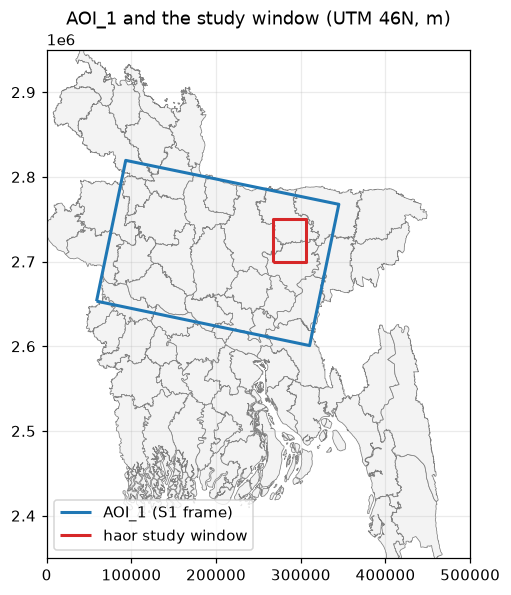

In [2]:
def read_quad_kml(path):  # AOI polygon from a Sentinel-1 overlay KML
    # read the corner coordinates of a Sentinel-1 overlay KML
    txt = Path(path).read_text()
    pts = re.search(r"<coordinates>(.*?)</coordinates>", txt, re.S).group(1).split()  # the corner coordinates
    return Polygon([tuple(map(float, p.split(",")[:2])) for p in pts])  # as a polygon in lon/lat

aoi = read_quad_kml(DATA / "AOI_1.kml")  # the AOI_1 frame
aoi_gdf = gpd.GeoDataFrame({"name": ["AOI_1"]}, geometry=[aoi], crs=4326)  # as a GeoDataFrame
aoi_utm = aoi_gdf.to_crs(CRS)  # in UTM 46N
print("AOI_1 bounds (lon/lat):", np.round(aoi.bounds, 3))  # its bounds
print(f"AOI_1 area: {aoi_utm.area.iloc[0] / 1e6:,.0f} km²")  # its area

# study window on a 20 m grid (pixel edges, UTM 46N)
WIN_BOUNDS = (266740, 2699860, 306000, 2750300)
WIN_RES = 20  # pixel size in metres
win_gb = GeoBox.from_bbox(WIN_BOUNDS, CRS, resolution=WIN_RES)  # the 20 m target grid of the window
win_poly = gpd.GeoDataFrame(geometry=[box(*WIN_BOUNDS)], crs=CRS)  # the window as a polygon
# size, area and containment
print("window:", win_gb.shape, "pixels;", f"{win_poly.area.iloc[0] / 1e6:,.0f} km²;",
      "inside AOI:", bool(aoi_utm.geometry.iloc[0].contains(win_poly.geometry.iloc[0])))

# district boundaries of Bangladesh
districts = gpd.read_file(CACHE / "geoBoundaries-BGD-ADM2_simplified.geojson").to_crs(CRS)
dist_win = districts[districts.intersects(win_poly.geometry.iloc[0])]  # districts that touch the window
print("districts in the window:", dist_win["shapeName"].tolist())  # their names

fig, ax = plt.subplots(figsize=(7, 6))  # one panel
districts.plot(ax=ax, fc="#f3f3f3", ec="grey", lw=0.5)
aoi_utm.boundary.plot(ax=ax, color="tab:blue", lw=2, label="AOI_1 (S1 frame)")  # the AOI outline
win_poly.boundary.plot(ax=ax, color="tab:red", lw=2, label="haor study window")  # the window outline
ax.set_xlim(0, 500000); ax.set_ylim(2.35e6, 2.95e6)  # map limits
ax.set_title("AOI_1 and the study window (UTM 46N, m)"); ax.legend(loc="lower left")  # title and legend
plt.show()  # draw

## Searching the Planetary Computer: inventory of the scenes


The STAC catalogue holds the `sentinel-1-rtc` collection. We keep only items on **relative orbit 150** that intersect the AOI. Each date is made of two consecutive slices (frames) along the track; they are mosaicked when loaded (`groupby="solar_day"`).


In [3]:
def search_s1():  # Sentinel-1 RTC scenes of orbit 150, grouped by date
    # Planetary Computer catalogue with URL signing
    client = pystac_client.Client.open(STAC, modifier=pc.sign_inplace)
    # every RTC item over the AOI in the period
    items = client.search(collections=["sentinel-1-rtc"], intersects=aoi, datetime=f"{START}/{END}").items()
    by = {}  # date -> items
    for it in items:  # each item
        if it.properties["sat:relative_orbit"] == ORBIT:  # on the chosen orbit
            by.setdefault(it.datetime.date().isoformat(), []).append(it)  # group by acquisition date
    return dict(sorted(by.items()))  # sorted by date

by_date = search_s1()  # search once
from shapely.geometry import shape  # geometry from GeoJSON
from shapely.ops import unary_union  # union of geometries

rows = []  # one row per date
for d, its in by_date.items():  # each date
    # share of the AOI covered by its slices
    cover = unary_union([shape(i.geometry) for i in its]).intersection(aoi).area / aoi.area
    # platform, slices, orbit direction and coverage
    rows.append({"date": pd.Timestamp(d), "platform": its[0].properties["platform"].upper(),
                 "slices": len(its), "orbit_state": its[0].properties["sat:orbit_state"],
                 "aoi_coverage": round(cover, 3)})
inv = pd.DataFrame(rows).set_index("date")  # as a table
inv["gap_days"] = inv.index.to_series().diff().dt.days  # days since the previous date
# number of dates and period
print(f"{len(inv)} dates on relative orbit {ORBIT} between {inv.index[0].date()} and {inv.index[-1].date()}")
# platforms and orbit direction
print(inv.platform.value_counts().to_dict(), "| orbit state:", inv.orbit_state.unique())
print("revisit gaps (days):", inv.gap_days.value_counts().sort_index().to_dict())  # revisit intervals
inv  # show the inventory

42 dates on relative orbit 150 between 2025-06-07 and 2026-10-31
{'SENTINEL-1A': 31, 'SENTINEL-1D': 11} | orbit state: <ArrowStringArray>
['descending']
Length: 1, dtype: str
revisit gaps (days): {7.0: 1, 12.0: 39, 36.0: 1}


,platform,slices,orbit_state,aoi_coverage,gap_days
date,,,,,
2025-06-07,SENTINEL-1A,2,descending,0.980,NaN
2025-07-13,SENTINEL-1A,2,descending,0.980,36.0
2025-07-25,SENTINEL-1A,2,descending,0.980,12.0
2025-08-06,SENTINEL-1A,2,descending,0.978,12.0
2025-08-18,SENTINEL-1A,2,descending,0.979,12.0
2025-08-30,SENTINEL-1A,2,descending,0.979,12.0
2025-09-11,SENTINEL-1A,2,descending,0.979,12.0
2025-09-23,SENTINEL-1A,2,descending,0.979,12.0
2025-10-05,SENTINEL-1A,2,descending,0.979,12.0


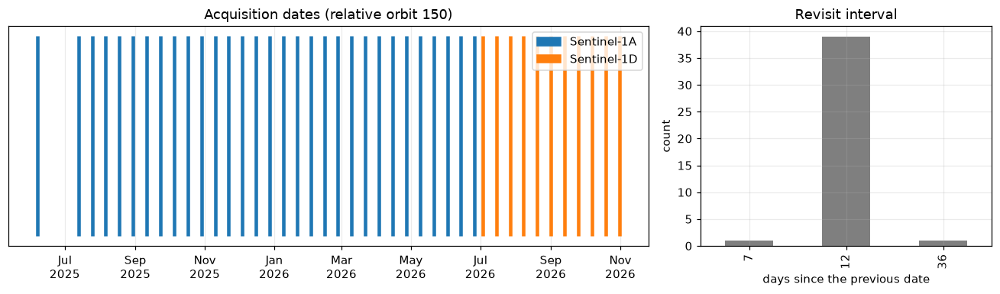

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [2.2, 1]})  # two panels
colors = {"SENTINEL-1A": "tab:blue", "SENTINEL-1D": "tab:orange"}  # platform colours
ax[0].vlines(inv.index, 0, 1, color=[colors.get(p, "grey") for p in inv.platform], lw=3)  # one line per date
ax[0].set_yticks([]); ax[0].set_title("Acquisition dates (relative orbit 150)")  # no y ticks; title
ax[0].xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))  # month/year labels
# platform legend
ax[0].legend(handles=[Patch(color=c, label=k.title()) for k, c in colors.items()], loc="upper right")
# revisit intervals as bars
inv.gap_days.dropna().astype(int).value_counts().sort_index().plot.bar(ax=ax[1], color="tab:grey")
# labels and title
ax[1].set_xlabel("days since the previous date"); ax[1].set_ylabel("count"); ax[1].set_title("Revisit interval")
plt.tight_layout(); plt.show()  # arrange and draw

**What the inventory shows.**

- The catalogue holds **42 dates** on this track for the AOI (the brief mentioned 41; the extra date is the first one, 7 June 2025, which is followed by a 36-day gap: no 19 June or 1 July acquisition exists in the archive for this orbit). Every date covers about 98 % of the AOI. We use all 42.
- The cadence is **12 days** (39 intervals), from Sentinel-1A until 26 June 2026 and from **Sentinel-1D** from 3 July 2026. The one 7-day interval is the hand-over between the two satellites. Both fly the same orbit, but their calibration need not be identical, so we check for a step between platforms in the *Quality check of the series* section.
- All scenes are *descending* (about 06:00 local time), which makes the series internally consistent. Early morning dew on the canopy can lift VV slightly, but it affects all dates in the same way.


## Downloading and caching the time series


The RTC assets are cloud-optimised GeoTIFFs. For each date we load both slices with `odc.stac`, mosaic them, resample onto our grid by **averaging** (10 m → 20 m or 200 m; averaging also acts as multilooking) and write one compressed NetCDF per date. The next run reuses the cache, so the download happens once (about 10 s per date for the regional grid). The `RUN_DOWNLOAD` flag lets you skip the step offline once the cache exists.


In [5]:
RUN_DOWNLOAD = True  # set to False to skip the download step
REG_BOUNDS, REG_RES = (57000, 2600000, 346000, 2820000), 200  # regional window at 200 m
reg_gb = GeoBox.from_bbox(REG_BOUNDS, CRS, resolution=REG_RES)  # its grid
# cache folders of the study window and the region
WIN_CACHE, REG_CACHE = CACHE / "rtc_haor_20m", CACHE / "aoi1_rtc_200m"

def cache_file(cache, d):  # cache file of one date
    return cache / f"S1_{d.replace('-', '')}.nc"  # ...

def fetch_date(d, gb, cache):  # load one date onto a grid and cache it (skipped when cached)
    f = cache_file(cache, d)  # its cache file
    if f.exists():  # cached already
        return f  # nothing to do
    # VV and VH of all slices of the date on the grid
    ds = odc.stac.load(by_date[d], bands=["vv", "vh"], geobox=gb, groupby="solar_day",
                       resampling="average", chunks={}).squeeze("time", drop=True)
    # keep only x and y coordinates; load
    ds = ds.drop_vars([v for v in ds.coords if v not in ("x", "y")]).compute()
    ds.attrs = {"date": d.replace("-", ""), "slices": len(by_date[d]),  # provenance
                "source": "Planetary Computer sentinel-1-rtc", "units": "gamma0 linear"}
    tmp = f.with_suffix(".tmp")  # write to a temporary file first
    # compressed NetCDF
    ds.to_netcdf(tmp, engine="h5netcdf", encoding={v: {"zlib": True, "complevel": 4} for v in ("vv", "vh")})
    tmp.rename(f)  # then rename (no half-written files)
    return f  # the cache file

def fetch_all(gb, cache, workers=4):  # load every uncached date in parallel
    cache.mkdir(parents=True, exist_ok=True)  # create the folder
    todo = [d for d in by_date if not cache_file(cache, d).exists()]  # dates still to download
    print(f"{cache.name}: {len(by_date) - len(todo)} cached, {len(todo)} to download")  # cached and missing
    t0 = time.time()  # start the timer
    with ThreadPoolExecutor(workers) as ex:  # four threads
        list(ex.map(lambda d: fetch_date(d, gb, cache), todo))  # download the missing dates
    if todo:  # something was downloaded
        print(f"  done in {time.time() - t0:.0f} s")  # time taken

if RUN_DOWNLOAD:  # download step on
    fetch_all(reg_gb, REG_CACHE)  # the 200 m regional stack
    fetch_all(win_gb, WIN_CACHE)  # the 20 m study-window stack

aoi1_rtc_200m: 42 cached, 0 to download
rtc_haor_20m: 42 cached, 0 to download


**Reference layers for the window.** We also fetch two independent products on the same 20 m grid:

- **ESA WorldCover 2021** (10 m, resampled by the *mode*): cropland (40), tree cover (10), built-up (50), permanent water bodies (80) and herbaceous wetland (90);
- **JRC Global Surface Water occurrence** (30 m): the percentage of months with water, 1984 to 2021.


In [6]:
def fetch_reference():  # ESA WorldCover 2021 and JRC water occurrence on the window grid, cached
    wc_f, jr_f = CACHE / "worldcover2021_20m_haor.nc", CACHE / "jrc_occurrence_20m_haor.nc"  # cache files
    if wc_f.exists() and jr_f.exists():  # both cached
        return wc_f, jr_f  # use them
    client = pystac_client.Client.open(STAC, modifier=pc.sign_inplace)  # catalogue with URL signing
    bbox = tuple(win_poly.to_crs(4326).total_bounds)  # window bounds in lon/lat
    # WorldCover 2021 items
    its = list(client.search(collections=["esa-worldcover"], bbox=bbox, datetime="2021-01-01/2021-12-31").items())
    # land-cover map on the 20 m grid (majority)
    wc = odc.stac.load(its, bands=["map"], geobox=win_gb, resampling="mode", chunks={}).isel(time=0).compute()["map"]
    wc.drop_vars("time", errors="ignore").to_dataset(name="worldcover").to_netcdf(wc_f)  # cache it
    its = list(client.search(collections=["jrc-gsw"], bbox=bbox).items())  # JRC surface-water items
    # water occurrence on the 20 m grid
    jr = odc.stac.load(its, bands=["occurrence"], geobox=win_gb, resampling="nearest", chunks={}).isel(time=0).compute()["occurrence"]
    jr.drop_vars("time", errors="ignore").to_dataset(name="occurrence").to_netcdf(jr_f)  # cache it
    return wc_f, jr_f  # the two files

wc_f, jr_f = fetch_reference()  # get or load them
print(wc_f.name, jr_f.name)  # their names

worldcover2021_20m_haor.nc jrc_occurrence_20m_haor.nc


## Regional view: the whole AOI at 200 m


The 200 m grid is a regional overview: at this scale each pixel averages 400 native 10 m pixels, so speckle is negligible and no filter is needed. Individual fields are not resolved, but the large-scale pattern of flooding and cropping is.


In [7]:
def load_stack(cache, label):  # stack cached dates along time
    fs = sorted(cache.glob("S1_*.nc"))  # the cache files in date order
    t = pd.to_datetime([f.stem[3:] for f in fs], format="%Y%m%d")  # dates from the file names
    parts = [xr.open_dataset(f).load() for f in fs]  # load every date
    ds = xr.concat(parts, dim=pd.Index(t, name="time"))  # concatenate along time
    ds = ds.rio.write_crs(CRS)  # attach the CRS
    # dates, size and missing share
    print(f"{label}: {ds.sizes['time']} dates, {ds.sizes['y']} x {ds.sizes['x']} px, "
          f"NaN fraction {float(ds.vh.isnull().mean()):.4f}")
    return ds  # the stack

reg = load_stack(REG_CACHE, "region 200 m")  # the 200 m regional stack
reg_vh = s1.to_db(reg.vh)  # VH in dB
reg_vv = s1.to_db(reg.vv)  # VV in dB
reg_vh.name, reg_vv.name = "vh_db", "vv_db"  # names

region 200 m: 42 dates, 1100 x 1445 px, NaN fraction 0.0000


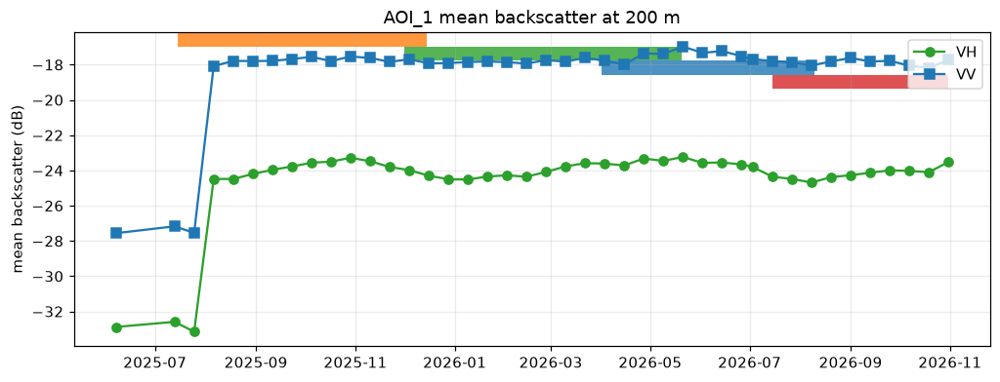

In [8]:
def seasons_bar(ax, y=1.0, h=0.06):  # draw the rice seasons on a time axis
    # coloured bars at the top of a time-series axis marking the rice seasons
    bars = [("Aman 2025", "2025-07-15", "2025-12-15", "tab:orange"),
            ("Boro 2026", "2025-12-01", "2026-05-20", "tab:green"),
            ("Aus 2026", "2026-04-01", "2026-08-10", "tab:blue"),
            ("Aman 2026", "2026-07-15", "2026-10-31", "tab:red")]
    for k, (name, a, b, c) in enumerate(bars):  # each season ...
        # its start and end as plot numbers
        a, b = mdates.date2num(pd.Timestamp(a)), mdates.date2num(pd.Timestamp(b))
        # a thin coloured band at the top of the axis
        ax.axvspan(a, b, ymin=1 - 0.045 * (k + 1), ymax=1 - 0.045 * k, color=c, alpha=0.8, lw=0)
    # season legend
    ax.legend(handles=[Patch(color=c, label=n) for n, _, _, c in bars], ncol=4, loc="lower center", fontsize=8)

fig, ax = plt.subplots(figsize=(11, 3.8))  # one panel
ax.plot(reg_vh.time, reg_vh.mean(["x", "y"]), "o-", color="tab:green", label="VH")  # mean VH per date
ax.plot(reg_vv.time, reg_vv.mean(["x", "y"]), "s-", color="tab:blue", label="VV")  # mean VV per date
ax.set_ylabel("mean backscatter (dB)"); ax.set_title("AOI_1 mean backscatter at 200 m")  # label and title
seasons_bar(ax); ax.legend(loc="upper right")  # season bands and legend
plt.show()  # draw

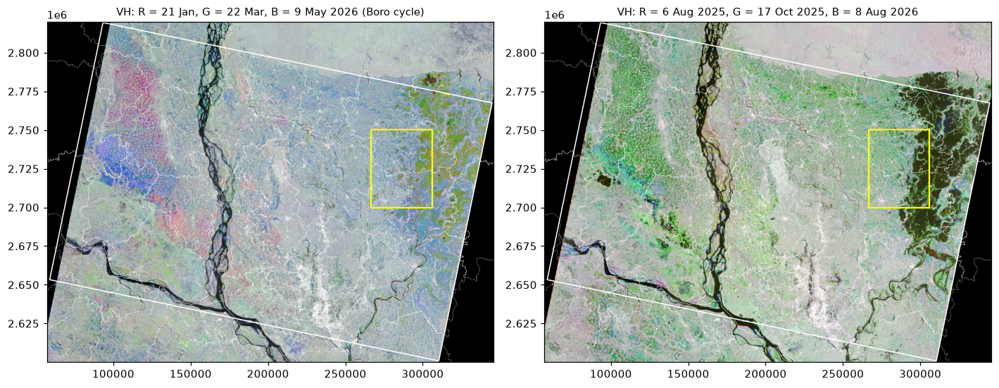

In [9]:
def rgb_composite(db, dates, lo=-26, hi=-8):  # three dates as an RGB image
    # three dates in R, G, B; each stretched between lo and hi dB
    ch = [db.sel(time=pd.Timestamp(d), method="nearest").values for d in dates]
    return np.clip((np.dstack(ch) - lo) / (hi - lo), 0, 1)  # stretch to 0-1

fig, ax = plt.subplots(1, 2, figsize=(13, 5.2))  # two panels
ext = [reg.x.min(), reg.x.max(), reg.y.min(), reg.y.max()]  # map extent
# two date triplets
for a, dates, ttl in [(ax[0], ["2026-01-21", "2026-03-22", "2026-05-09"], "VH: R = 21 Jan, G = 22 Mar, B = 9 May 2026 (Boro cycle)"),
                      (ax[1], ["2025-08-06", "2025-10-17", "2026-08-08"], "VH: R = 6 Aug 2025, G = 17 Oct 2025, B = 8 Aug 2026")]:
    a.imshow(rgb_composite(reg_vh, dates), extent=ext, origin="upper")  # the RGB composite
    # AOI and window outlines
    aoi_utm.boundary.plot(ax=a, color="white", lw=1); win_poly.boundary.plot(ax=a, color="yellow", lw=1.5)
    districts.boundary.plot(ax=a, color="white", lw=0.3, alpha=0.6)  # district boundaries
    # limits, title, no grid
    a.set_xlim(ext[0], ext[1]); a.set_ylim(ext[2], ext[3]); a.set_title(ttl, fontsize=10); a.grid(False)
plt.tight_layout(); plt.show()  # arrange and draw

**How to read the composites.** In the left image, a pixel that is *dark in January* (flood or puddled field), *bright in March* (canopy) and *dark again in May* (after harvest) shows in **green** tones; permanent water is dark on all three dates (black); trees and settlements are bright on all three (light grey). The yellow rectangle is the haor study window, at the western edge of the Sylhet-Kishoreganj haor basin; the olive-green area to its east and north is the Boro landscape. The large red and blue patches in the west are regions whose crop calendar differs: red means high in January and low later, blue means high only in May. In the right image the haor basin is **black**: dark on 6 Aug 2025, 17 Oct 2025 and 8 Aug 2026, that is, flooded in the monsoon of both years and still wet in October. Pale green marks upland fields that are dark in August and brighter in October, the typical Aman pattern.


## Loading the haor window, quality control and speckle filtering


In [10]:
win = load_stack(WIN_CACHE, "window 20 m")  # the 20 m study-window stack
T = win.sizes["time"]  # number of dates
times = win.time.values  # the dates
# grid and memory
print("grid:", win.sizes["y"], "x", win.sizes["x"], "| memory (vv+vh):", f"{(win.vv.nbytes + win.vh.nbytes) / 1e9:.1f} GB")

window 20 m: 42 dates, 2522 x 1963 px, NaN fraction 0.0000
grid: 2522 x 1963 | memory (vv+vh): 1.7 GB


### Quality check of the series

A scene-wide mean is dominated by flooding and crop growth, so it cannot reveal a calibration problem. Tree cover (ESA WorldCover class 10) has almost no seasonal signal in VH, so we use it as a **stable target**: we compare its mean VH on each date with a rolling median and flag deviations larger than 3 robust standard deviations. The same series shows whether there is a step between **Sentinel-1A** (until 26 June 2026) and **Sentinel-1D** (from 3 July 2026).


flagged dates: none
mean VH over trees: S1A -11.85 dB, S1D -11.76 dB (difference +0.09 dB); overall SD 0.30 dB


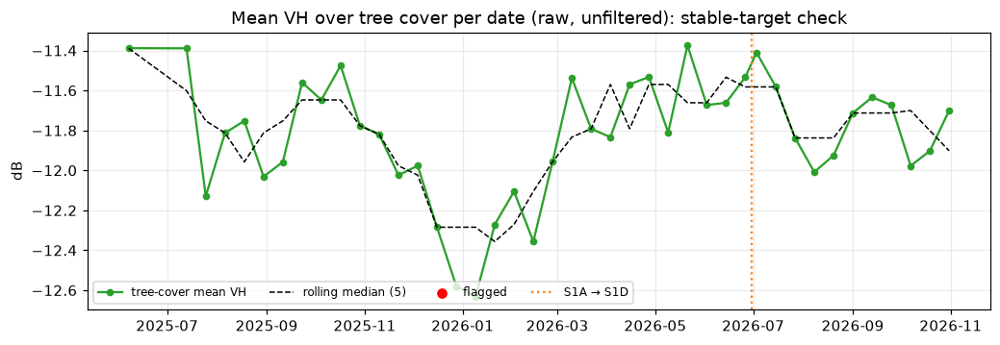

In [11]:
wc_arr = xr.open_dataset(wc_f).worldcover.values.astype("uint8")  # WorldCover classes on the window
tree_mask = wc_arr == 10  # tree-cover pixels (class 10)
tree_raw = 10 * np.log10(win.vh.values[:, tree_mask].mean(1))     # mean linear power over trees, in dB
mean_raw = pd.Series(tree_raw, index=pd.DatetimeIndex(times))  # as a dated series
roll = mean_raw.rolling(5, center=True, min_periods=3).median()  # rolling median of five dates
resid = mean_raw - roll  # deviations from it
z = resid / (1.4826 * np.median(np.abs(resid - np.median(resid))))  # robust z-score (median absolute deviation)
flag = z.abs() > 3  # dates more than 3 robust SD away
print("flagged dates:", [d.date().isoformat() for d in mean_raw.index[flag]] or "none")  # flagged dates
# Sentinel-1A dates and Sentinel-1D dates
s1a = mean_raw[mean_raw.index < "2026-07-01"]; s1d = mean_raw[mean_raw.index >= "2026-07-01"]
# mean of each and the overall spread
print(f"mean VH over trees: S1A {s1a.mean():.2f} dB, S1D {s1d.mean():.2f} dB (difference {s1d.mean() - s1a.mean():+.2f} dB); "
      f"overall SD {mean_raw.std():.2f} dB")

fig, ax = plt.subplots(figsize=(11, 3.4))  # one panel
# tree-cover mean per date
ax.plot(mean_raw.index, mean_raw.values, "o-", ms=4, color="tab:green", label="tree-cover mean VH")
ax.plot(roll.index, roll.values, "--", color="k", lw=1, label="rolling median (5)")  # its rolling median
ax.scatter(mean_raw.index[flag], mean_raw[flag], color="red", zorder=3, label="flagged")  # flagged dates in red
# the switch from Sentinel-1A to 1D
ax.axvline(pd.Timestamp("2026-06-30"), color="tab:orange", ls=":", label="S1A → S1D")
# label, title and legend
ax.set_ylabel("dB"); ax.set_title("Mean VH over tree cover per date (raw, unfiltered): stable-target check"); ax.legend(ncol=4, fontsize=8)
plt.show()  # draw

### Multi-temporal speckle filtering

We apply the Quegan & Yu filter (`multitemporal_speckle_filter`) with a 5 × 5 Lee spatial estimator to both polarisations, then compare one date before and after, and with a single-date Lee filter of the same size. The ENL is measured over a homogeneous cropland block of 30 × 30 pixels.


In [12]:
t0 = time.time()  # start the timer
vh_f = s1.multitemporal_speckle_filter(win.vh, spatial="lee", size=5)  # multi-temporal Lee filter on VH
vv_f = s1.multitemporal_speckle_filter(win.vv, spatial="lee", size=5)  # and on VV
print(f"filtered {T} dates x 2 polarisations in {time.time() - t0:.0f} s")  # time taken
vh_db = s1.to_db(vh_f).astype("float32"); vv_db = s1.to_db(vv_f).astype("float32")  # both in dB
vh_db.name, vv_db.name = "vh_db", "vv_db"  # names

filtered 42 dates x 2 polarisations in 20 s


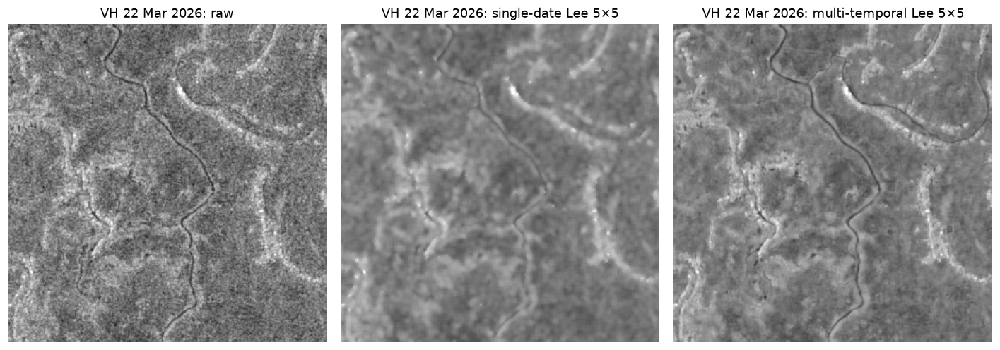

ENL over a homogeneous cropland block (rows 1298:1328, cols 553:583):
  raw                      5.9
  single-date Lee         21.1
  multi-temporal Lee      14.8


In [13]:
k = int(np.argmin(np.abs(times - np.datetime64("2026-03-22"))))  # the date closest to 22 March 2026
r0, c0, n = 1000, 900, 300  # corner and size of a zoom
sl = (slice(r0, r0 + n), slice(c0, c0 + n))  # the zoom window
raw = win.vh.isel(time=k).values[sl]  # raw VH
single = speckle.lee(win.vh.isel(time=k).values, 5)[sl]  # single-date Lee
multi = vh_f.isel(time=k).values[sl]  # multi-temporal Lee
fig, ax = plt.subplots(1, 3, figsize=(13, 4.4))  # three panels
# each version
for a, im, t in zip(ax, [raw, single, multi], ["raw", "single-date Lee 5×5", "multi-temporal Lee 5×5"]):
    # VH in dB
    a.imshow(10 * np.log10(im), cmap="gray", vmin=-25, vmax=-5); a.set_title(f"VH 22 Mar 2026: {t}"); a.axis("off")
plt.tight_layout(); plt.show()  # arrange and draw

# homogeneous block: lowest coefficient of variation of the temporal mean among cropland blocks
wc_arr = xr.open_dataset(wc_f).worldcover.values
tm = win.vh.mean("time").values  # temporal mean of VH
best, bpos = np.inf, None  # best block so far
for _ in range(400):  # 400 random tries
    r, c = rng.integers(0, tm.shape[0] - 30), rng.integers(0, tm.shape[1] - 30)  # a random 30 x 30 block
    if (wc_arr[r:r + 30, c:c + 30] == 40).all():  # entirely cropland
        cv = tm[r:r + 30, c:c + 30].std() / tm[r:r + 30, c:c + 30].mean()  # its coefficient of variation
        if cv < best:  # lower than the best so far
            best, bpos = cv, (r, c)  # keep it
r, c = bpos  # the most homogeneous block
blk = (slice(r, r + 30), slice(c, c + 30))  # its window
# equivalent number of looks of each version
enl = {"raw": speckle.enl_estimate(win.vh.isel(time=k).values[blk]),
       "single-date Lee": speckle.enl_estimate(speckle.lee(win.vh.isel(time=k).values, 5)[blk]),
       "multi-temporal Lee": speckle.enl_estimate(vh_f.isel(time=k).values[blk])}
print("ENL over a homogeneous cropland block (rows %d:%d, cols %d:%d):" % (r, r + 30, c, c + 30))  # header
for kk, vv_ in enl.items():  # each version
    print(f"  {kk:20s} {vv_:7.1f}")  # its ENL

Both filters raise the ENL over the raw 20 m data (which are already block-averaged from 10 m). In this block the single-date Lee filter gives the higher ENL, because it smooths each date spatially much more; the multi-temporal filter smooths less spatially but borrows information from the other dates, and it does so without mixing the dates of a pixel's series. ENL measures noise reduction only. It does not measure how well edges or small fields are kept, so we judge that from the images. The numbers are indicative: a "homogeneous" field still contains texture, which lowers the ENL estimate.


## Reference layers and temporal signatures


In [14]:
jrc = xr.open_dataset(jr_f).occurrence.values.astype("float32")  # JRC water occurrence (% of time)
# WorldCover code -> name
WC_NAMES = {10: "Tree cover", 20: "Shrubland", 30: "Grassland", 40: "Cropland", 50: "Built-up",
            60: "Bare / sparse", 80: "Permanent water", 90: "Herbaceous wetland"}
# share of each WorldCover class
tab = pd.Series(wc_arr.ravel()).map(WC_NAMES).value_counts(normalize=True).mul(100).round(1)
print("WorldCover composition of the window (%):"); print(tab.to_string())  # header and table

WorldCover composition of the window (%):
Cropland              72.5
Tree cover            19.4
Herbaceous wetland     4.6
Permanent water        2.3
Built-up               0.6
Grassland              0.4
Bare / sparse          0.1
Shrubland              0.0


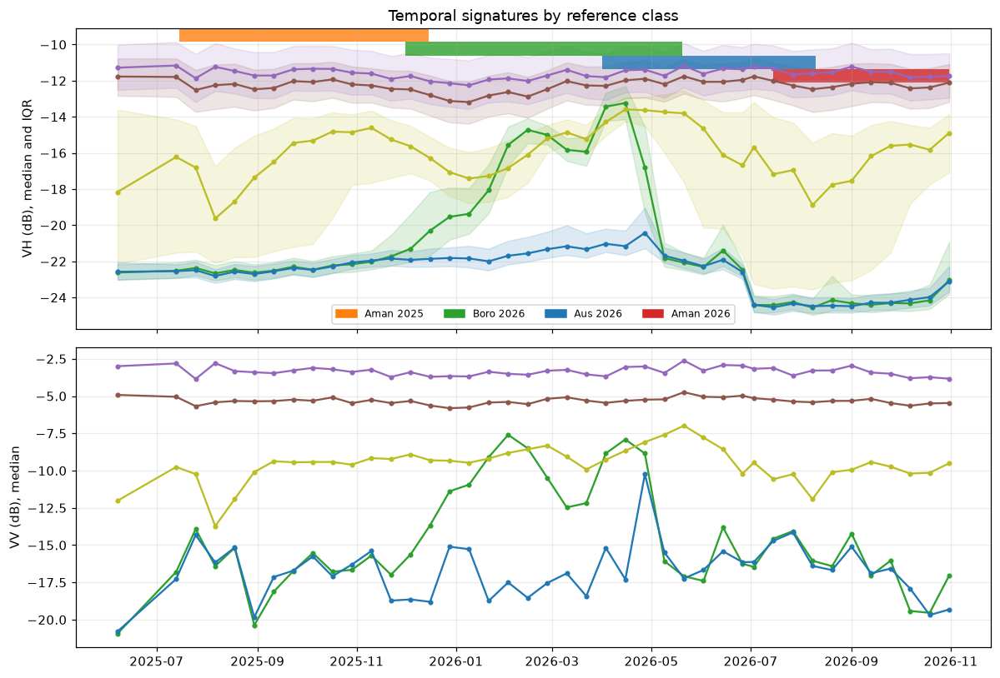

In [15]:
# reference pixel groups
groups = {"Herbaceous wetland (WC 90)": wc_arr == 90, "Cropland (WC 40)": wc_arr == 40,
          "Permanent water (JRC > 90 %)": jrc > 90, "Tree cover (WC 10)": wc_arr == 10, "Built-up (WC 50)": wc_arr == 50}
cols = ["tab:green", "tab:olive", "tab:blue", "tab:brown", "tab:purple"]  # their colours
fig, ax = plt.subplots(2, 1, figsize=(11, 7.5), sharex=True)  # two panels sharing the time axis
for (name, m), c in zip(groups.items(), cols):  # each group
    q = np.nanpercentile(vh_db.values[:, m], [25, 50, 75], axis=1)  # VH quartiles over its pixels per date
    ax[0].plot(vh_db.time, q[1], "-o", ms=3, color=c, label=f"{name} (n={m.sum():,})")  # median line
    ax[0].fill_between(vh_db.time, q[0], q[2], color=c, alpha=0.15)  # interquartile band
    ax[1].plot(vv_db.time, np.nanmedian(vv_db.values[:, m], axis=1) - 0, "-o", ms=3, color=c)  # VV median
ax[0].set_ylabel("VH (dB), median and IQR"); ax[1].set_ylabel("VV (dB), median")  # y labels
# legend and title
ax[0].legend(fontsize=8, ncol=2, loc="lower right"); ax[0].set_title("Temporal signatures by reference class")
seasons_bar(ax[0])  # season bands
plt.tight_layout(); plt.show()  # arrange and draw

**Reading the signatures.**

- **Built-up** and **tree cover** stay high (about −11 to −12 dB VH) on every date: no seasonality, and VH alone does not separate them. We therefore take them from WorldCover and merge them into one class, **trees and settlements**.
- **Permanent water** is lowest in the monsoon (below −24 dB) and rises a little in the dry season (wind, shallow water, vegetation).
- **Herbaceous wetland** (the haor floor) is flooded from June to December (VH ≈ −22 to −24 dB), then rises steeply from January to a peak in April (≈ −13 dB) and falls at harvest. This is the Boro cycle in a wetland. The pre-monsoon flood returns in May.
- **Cropland** is a mixture, so its median is flatter. The IQR band shows that it contains both rice and non-rice pixels.
- The stable-target check in the *Quality check of the series* section shows **no meaningful step between Sentinel-1A and 1D** over trees, so the two platforms can be treated as one series.


## Temporal features and multi-temporal composites


['vh_mean', 'vh_std', 'vh_min', 'vh_max', 'vh_amp', 'vh_day_min', 'vh_day_max', 'vv_mean', 'vv_std', 'vhvv_mean']


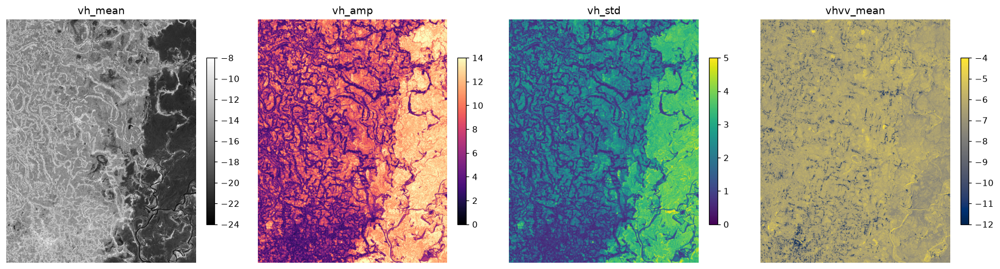

In [16]:
def temporal_features(vh, vv):  # per-pixel statistics of the VH and VV series
    # per-pixel temporal statistics of the dB series
    t = vh.time.values.astype("datetime64[D]")
    days = (t - t[0]).astype(int).astype("float32")  # days since the first date
    a = vh.values  # VH values (time, y, x)
    amp = a.max(0) - a.min(0)  # amplitude
    # the ten temporal features
    f = {"vh_mean": a.mean(0), "vh_std": a.std(0), "vh_min": a.min(0), "vh_max": a.max(0), "vh_amp": amp,
         "vh_day_min": days[a.argmin(0)], "vh_day_max": days[a.argmax(0)],
         "vv_mean": vv.values.mean(0), "vv_std": vv.values.std(0),
         "vhvv_mean": (vh.values - vv.values).mean(0)}
    tmpl = vh.isel(time=0, drop=True)  # a 2-D template
    # as a Dataset on the window grid
    return xr.Dataset({k: tmpl.copy(data=v.astype("float32")) for k, v in f.items()})

feat_stats = temporal_features(vh_db, vv_db)  # compute them
print(list(feat_stats.data_vars))  # feature names
fig, ax = plt.subplots(1, 4, figsize=(16, 4.4))  # four panels
# four features with their colour ranges
for a, (k, cm, lim) in zip(ax, [("vh_mean", "gray", (-24, -8)), ("vh_amp", "magma", (0, 14)),
                                ("vh_std", "viridis", (0, 5)), ("vhvv_mean", "cividis", (-12, -4))]):
    # draw one feature
    im = a.imshow(feat_stats[k].values, cmap=cm, vmin=lim[0], vmax=lim[1]); a.set_title(k); a.axis("off")
    plt.colorbar(im, ax=a, fraction=0.04)  # colour bar
plt.tight_layout(); plt.show()  # arrange and draw

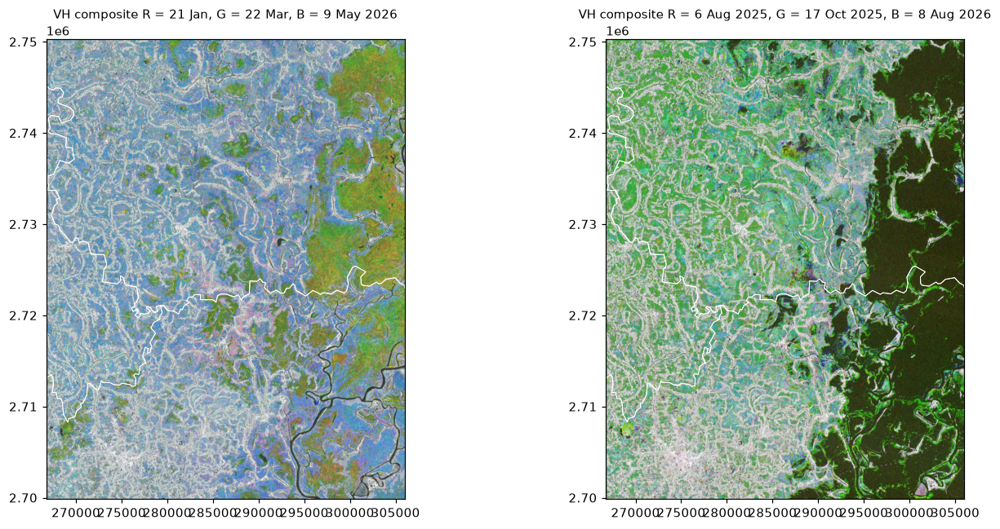

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(13, 6))  # two panels
# map extent of the window
ext_w = [float(win.x.min()), float(win.x.max()), float(win.y.min()), float(win.y.max())]
# two date triplets
for a, dates, ttl in [(ax[0], ["2026-01-21", "2026-03-22", "2026-05-09"], "R = 21 Jan, G = 22 Mar, B = 9 May 2026"),
                      (ax[1], ["2025-08-06", "2025-10-17", "2026-08-08"], "R = 6 Aug 2025, G = 17 Oct 2025, B = 8 Aug 2026")]:
    # VH composite; title; no grid
    a.imshow(rgb_composite(vh_db, dates), extent=ext_w); a.set_title("VH composite " + ttl, fontsize=10); a.grid(False)
    dist_win.boundary.plot(ax=a, color="white", lw=0.6)  # district outlines
    a.set_xlim(ext_w[0], ext_w[1]); a.set_ylim(ext_w[2], ext_w[3])  # limits
plt.tight_layout(); plt.show()  # arrange and draw

## Water and wetland mask


We build the water mask in two ways and compare them with the independent JRC product.

1. **One wet date.** `sar.apps.flood_map` applies a tile-based Otsu threshold to the VH image of the date with the most water (8 August 2026, in the middle of the 2026 monsoon).
2. **Water frequency.** The fraction of the 42 dates on which VH is below −18 dB separates **permanent water** (frequency ≥ 0.9), **seasonal water** (0.4 to 0.9) and land. A haor field under Boro is dark for half of the year, so it falls in the seasonal class; this is why seasonal water cannot be separated from Boro paddy without the rest of the series (see *Rule-based paddy mapping and event dates*).


flood_map variables: ['water']


water on 2026-08-08 (Otsu): 47.3 % of the window
permanent water (SAR frequency ≥ 0.9): 1.55 %;  JRC occurrence ≥ 80 %: 0.73 %
SAR permanent water vs JRC ≥ 80 %: {'IoU': 0.33, 'recall': 0.78, 'precision': 0.37}
SAR permanent water vs WorldCover water: {'IoU': 0.37, 'recall': 0.45, 'precision': 0.67}
seasonal water: 29.0 %


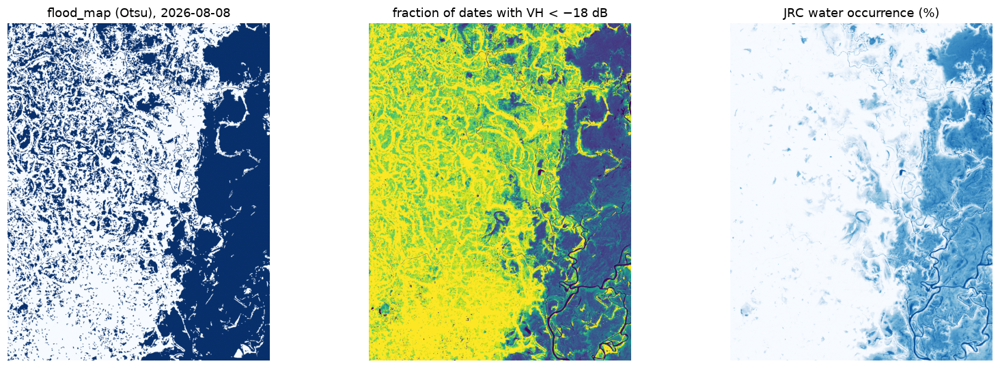

In [18]:
wet_date = pd.Timestamp("2026-08-08")  # a wet-season date
# water map with split-based Otsu thresholding on VH
fm = sarapps.flood_map(vh_db.sel(time=wet_date), method="split_otsu", db_input=True, min_pixels=20)
print("flood_map variables:", list(fm.data_vars))  # its variables
# the water mask
water_wet = fm["flood"].values.astype(bool) if "flood" in fm else fm[list(fm.data_vars)[0]].values.astype(bool)

WATER_DB = -18.0  # VH threshold for open water
water_freq = (vh_db.values < WATER_DB).mean(0)  # share of dates below it
perm_water = water_freq >= 0.9  # water on at least 90 % of dates
seasonal_water = (water_freq >= 0.4) & ~perm_water  # water on 40-90 % of dates
jrc_perm = jrc >= 80  # JRC water present at least 80 % of the time

def overlap(a, b):  # agreement of two masks
    # IoU, recall and precision
    return {"IoU": float((a & b).sum() / (a | b).sum()), "recall": float((a & b).sum() / b.sum()),
            "precision": float((a & b).sum() / a.sum())}
# water on the wet date
print(f"water on {wet_date.date()} (Otsu): {water_wet.mean() * 100:.1f} % of the window")
# permanent water from SAR and from JRC
print(f"permanent water (SAR frequency ≥ 0.9): {perm_water.mean() * 100:.2f} %;  JRC occurrence ≥ 80 %: {jrc_perm.mean() * 100:.2f} %")
# SAR against JRC
print("SAR permanent water vs JRC ≥ 80 %:", {k: round(v, 2) for k, v in overlap(perm_water, jrc_perm).items()})
# SAR against WorldCover water
print("SAR permanent water vs WorldCover water:", {k: round(v, 2) for k, v in overlap(perm_water, wc_arr == 80).items()})
print(f"seasonal water: {seasonal_water.mean() * 100:.1f} %")  # seasonal water

fig, ax = plt.subplots(1, 3, figsize=(15, 5))  # three panels
ax[0].imshow(water_wet, cmap="Blues"); ax[0].set_title(f"flood_map (Otsu), {wet_date.date()}")  # wet-date water
# water frequency
ax[1].imshow(water_freq, cmap="viridis_r", vmin=0, vmax=1); ax[1].set_title("fraction of dates with VH < −18 dB")
ax[2].imshow(jrc, cmap="Blues", vmin=0, vmax=100); ax[2].set_title("JRC water occurrence (%)")  # JRC occurrence
for a in ax: a.axis("off")  # no axes
plt.tight_layout(); plt.show()  # arrange and draw

The SAR permanent-water layer recovers most of the JRC water (high recall) but also maps about twice as much water: a threshold on VH below −18 dB on 90 % of dates includes shallow, long-flooded haor beds and dark, wet fields that JRC records with a lower occurrence. We do not have a reference that tells which is right, so we use the SAR layer only as a mask for the **permanent water** class; it is a conservative choice for paddy because paddy fields drain for part of the year.


## Rule-based paddy mapping and event dates


Every rule is written in terms of the VH dB series. For each season we run `sar.apps.rice_map`, which looks for the *flood minimum* followed by a *rise within a window*. For Boro we add the **harvest-drop rule** that the GeoLattice function does not have, since in the haors the pre-harvest low is the end of the monsoon flood.

| Season | Series slice | `flood_db` | `rise_db` | `window_days` | `min_peak_db` | Extra rule |
|---|---|---|---|---|---|---|
| Aman 2025 | 13 Jul, 22 Nov 2025 | −18 | 4 | 100 | −16 | none (harvest is at the end of the slice) |
| **Boro 2026** | 1 Dec 2025 to 27 Apr 2026 | −19 | 5 | 150 | −16 | **harvest drop** ≥ 4 dB from the April peak to the May-June minimum |
| Aus 2026 | 9 May, 8 Aug 2026 | −18 | 4 | 70 | −16 | none |
| Aman 2026 (early) | 3 Jul, 31 Oct 2026 | −18 | 4 | 100 | −16 | none |

A **strict** version of each rule (deeper minimum, larger rise and higher peak) is used later to select training pixels that are very likely to be rice. Pixels that pass the loose rules but fail the strict ones are treated as *ambiguous* and left out of training.


In [19]:
RULES = {  # (slice start, slice end, flood_db, rise_db, window_days, min_peak_db) for loose and strict
    "aman25": dict(sl=("2025-07-13", "2025-11-22"), loose=(-18, 4, 100, -16), strict=(-19, 6, 100, -15)),
    "boro":   dict(sl=("2025-12-01", "2026-04-27"), loose=(-19, 5, 150, -16), strict=(-20, 7, 150, -15)),
    "aus":    dict(sl=("2026-05-09", "2026-08-08"), loose=(-18, 4, 70, -16),  strict=(-19, 6, 70, -15)),
    "aman26": dict(sl=("2026-07-03", "2026-10-31"), loose=(-18, 4, 100, -16), strict=(-19, 6, 100, -15)),
}
HARVEST_DROP = {"loose": 4.0, "strict": 5.0}  # VH drop that marks the Boro harvest

def rice_rules(db, strict=False):  # seasonal rice masks and event dates
    # seasonal rice masks and event dates from a VH dB series (time, y, x)
    lvl = "strict" if strict else "loose"
    out = {}  # masks and dates
    for name, r in RULES.items():  # each season
        fl, rs, wd, pk = r[lvl]  # its thresholds
        # GeoLattice rice rule: flooding then a VH rise
        res = sarapps.rice_map(db.sel(time=slice(*r["sl"])), db_input=True, flood_db=fl, rise_db=rs,
                               window_days=wd, min_peak_db=pk)
        out[name] = res["rice"].values.astype(bool)  # the rice mask
        out[name + "_date"] = res["transplanting_date"].values  # the transplanting (flood-minimum) date
    # Boro harvest rule: April peak vs May-June minimum
    pk = db.sel(time=slice("2026-04-03", "2026-04-27")).max("time").values
    post = db.sel(time=slice("2026-05-09", "2026-06-02")).min("time").values  # VH minimum in May-June
    drop = HARVEST_DROP[lvl]  # drop required
    out["boro"] &= (pk - post) >= drop  # Boro must also show the harvest drop
    # harvest date: first date from 15 April at which VH has dropped by `drop` dB below the peak
    late = db.sel(time=slice("2026-04-15", "2026-06-14"))
    dropped = late.values <= (pk[None] - drop)  # dates where VH fell far enough
    first = np.where(dropped.any(0), dropped.argmax(0), -1)  # first such date (-1 if none)
    tv = late.time.values.astype("datetime64[D]")  # the dates
    # harvest date
    out["boro_harvest_date"] = np.where(first >= 0, tv[np.clip(first, 0, None)], np.datetime64("NaT"))
    # dates only where Boro is mapped
    out["boro_date"] = np.where(out["boro"], out["boro_date"], np.datetime64("NaT"))
    out["boro_harvest_date"] = np.where(out["boro"], out["boro_harvest_date"], np.datetime64("NaT"))  # ...
    return out  # masks and dates

t0 = time.time()  # start the timer
loose = rice_rules(vh_db)  # loose rules
strict = rice_rules(vh_db, strict=True)  # strict rules
print(f"rules done in {time.time() - t0:.0f} s")  # time taken
# share and area of each season
summary = pd.DataFrame({k: {"loose %": loose[k].mean() * 100, "strict %": strict[k].mean() * 100,
                            "loose km²": loose[k].sum() * 4e-4}
                        for k in ["boro", "aman25", "aman26", "aus"]}).T.round(2)
summary  # show it

rules done in 7 s


,loose %,strict %,loose km²
boro,20.05,10.34,397.11
aman25,32.77,19.52,649.00
aman26,30.90,16.23,611.99
aus,5.50,1.80,108.94


In [20]:
# plausibility against WorldCover: where does each rule fire?
rows = {}
for k in ["boro", "aman25", "aman26", "aus"]:  # each season
    # share of each WorldCover class it flags
    rows[k] = {WC_NAMES[c]: loose[k][wc_arr == c].mean() * 100 for c in (10, 40, 50, 80, 90)}
# as a table
pd.DataFrame(rows).T.round(1).rename_axis("share of each WorldCover class flagged by the loose rule (%)")

,Tree cover,Cropland,Built-up,Permanent water,Herbaceous wetland
share of each WorldCover class flagged by the loose rule (%),,,,,
boro,0.0,21.6,0.0,15.1,85.8
aman25,2.0,43.9,0.8,9.3,5.4
aman26,1.6,41.4,0.4,11.5,5.2
aus,0.2,7.3,0.1,1.4,1.9


**Plausibility check (no accuracy claim).** The Boro rule flags most of the *herbaceous wetland* pixels (the haor floor, where Boro is the dominant crop) and essentially no tree-cover or built-up pixels. The Aman rules fire mostly on *cropland*. Aus is rare in the haor basin, so its small share is expected. These are consistency checks against an independent land-cover layer, not a validation of the paddy maps.


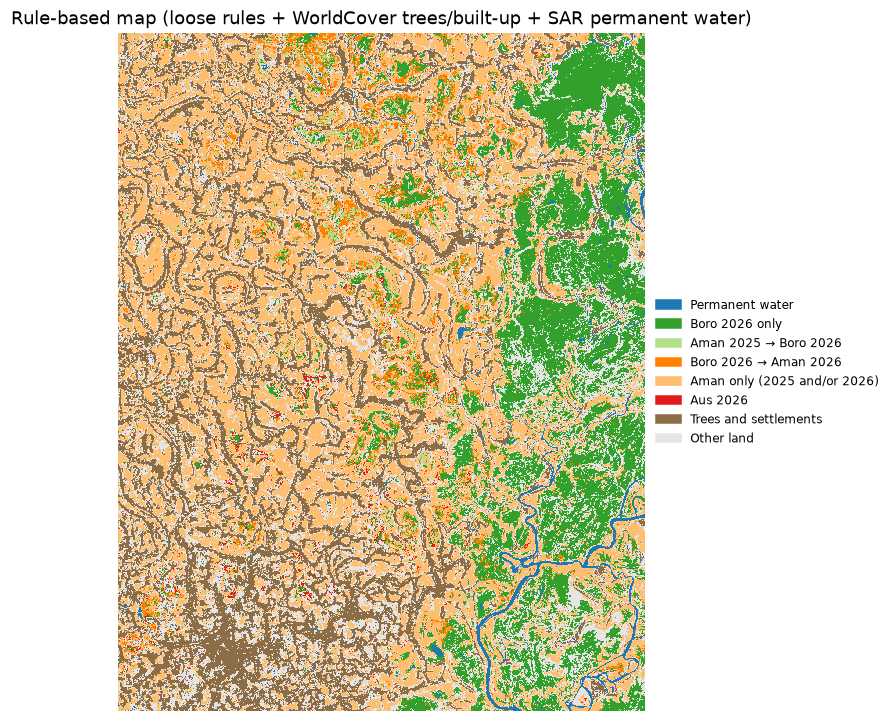

,class,km²,% of window
1,Permanent water,30.7,1.5
2,Boro 2026 only,310.5,15.7
3,Aman 2025 → Boro 2026,24.9,1.3
4,Boro 2026 → Aman 2026,60.3,3.0
5,Aman only (2025 and/or 2026),670.0,33.8
6,Aus 2026,14.9,0.8
7,Trees and settlements,395.7,20.0
8,Other land,473.3,23.9


In [21]:
# map classes
CLASSES = {1: "Permanent water", 2: "Boro 2026 only", 3: "Aman 2025 → Boro 2026", 4: "Boro 2026 → Aman 2026",
           5: "Aman only (2025 and/or 2026)", 6: "Aus 2026", 7: "Trees and settlements", 8: "Other land"}
PALETTE = {1: "#1f78b4", 2: "#33a02c", 3: "#b2df8a", 4: "#ff7f00", 5: "#fdbf6f", 6: "#e31a1c", 7: "#8c6d46",
           8: "#e5e5e5"}

def compose_classes(masks):  # combine the season masks into one map
    # priority: later assignments overwrite earlier ones; reference layer (trees, built-up) and water on top
    cls = np.full(wc_arr.shape, 8, "int16")
    cls[masks["aus"]] = 6  # Aus 2026
    cls[masks["aman25"] | masks["aman26"]] = 5  # Aman 2025 or 2026
    cls[masks["boro"]] = 2  # Boro 2026
    cls[masks["boro"] & masks["aman25"]] = 3  # Boro after Aman 2025
    cls[masks["boro"] & masks["aman26"]] = 4  # Boro followed by Aman 2026
    cls[(wc_arr == 10) | (wc_arr == 50)] = 7      # VH alone cannot separate trees from buildings
    cls[perm_water] = 1  # permanent water on top
    return cls  # the class map

cls_rule = compose_classes(loose)  # map from the loose rules
cls_strict = compose_classes(strict)  # map from the strict rules

def show_classes(ax, arr, title):  # draw a class map
    # colours and class boundaries
    cmap = ListedColormap([PALETTE[k] for k in CLASSES]); norm = BoundaryNorm(np.arange(0.5, 9.5), 8)
    # the map, title and no axes
    ax.imshow(arr, cmap=cmap, norm=norm, interpolation="nearest"); ax.set_title(title); ax.axis("off")

def class_legend(ax):  # class legend beside an axis
    # one patch per class
    ax.legend(handles=[Patch(color=PALETTE[k], label=v) for k, v in CLASSES.items()], loc="center left",
              bbox_to_anchor=(1, 0.5), fontsize=8, frameon=False)

fig, ax = plt.subplots(figsize=(9, 8))  # one panel
# the rule-based map and its legend
show_classes(ax, cls_rule, "Rule-based map (loose rules + WorldCover trees/built-up + SAR permanent water)"); class_legend(ax)
plt.show()  # draw
cnt = pd.Series(cls_rule.ravel()).value_counts().sort_index()  # pixels per class
# area and share per class
pd.DataFrame({"class": [CLASSES[k] for k in cnt.index], "km²": (cnt.values * 4e-4).round(1),
              "% of window": (cnt.values / cls_rule.size * 100).round(1)}, index=cnt.index)

### Event dates: Boro flood-minimum and harvest

The `transplanting_date` of `rice_map` is the date of the VH minimum before the rise. In the haors this is the date at which the flood has receded and the field is being prepared, a good proxy for **transplanting**. The harvest date is the first date at which VH is at least 4 dB below the April peak. Dates have a resolution of the 12-day revisit.


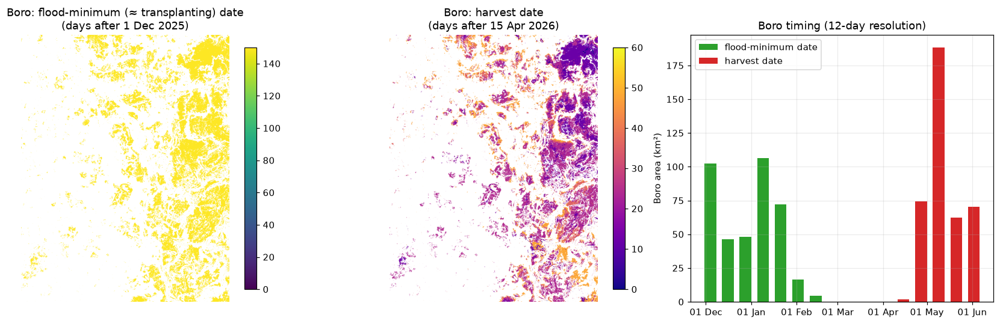

In [22]:
def as_doy_months(a):  # dates as a pandas Series (kept for reference)
    d = pd.to_datetime(pd.Series(a.ravel()))  # ...
    return d  # ...

fig, ax = plt.subplots(1, 3, figsize=(16, 5))  # three panels
bd, hd = loose["boro_date"], loose["boro_harvest_date"]  # Boro transplanting and harvest dates
ref = np.datetime64("2025-12-01")  # reference date
# days after 1 December 2025
im0 = ax[0].imshow(np.where(np.isnat(bd), np.nan, (bd - ref).astype(float)), cmap="viridis", vmin=0, vmax=150)
ax[0].set_title("Boro: flood-minimum (≈ transplanting) date\n(days after 1 Dec 2025)")  # title
ref2 = np.datetime64("2026-04-15")  # reference date for harvest
# days after 15 April 2026
im1 = ax[1].imshow(np.where(np.isnat(hd), np.nan, (hd - ref2).astype(float)), cmap="plasma", vmin=0, vmax=60)
ax[1].set_title("Boro: harvest date\n(days after 15 Apr 2026)")  # title
for a, im in zip(ax[:2], [im0, im1]):  # both maps
    a.axis("off"); plt.colorbar(im, ax=a, fraction=0.04)  # no axes; colour bar
tvals = pd.to_datetime(bd[~np.isnat(bd)]).value_counts().sort_index()  # Boro area per transplanting date
hvals = pd.to_datetime(hd[~np.isnat(hd)]).value_counts().sort_index()  # Boro area per harvest date
ax[2].bar(tvals.index, tvals.values * 4e-4, width=8, color="tab:green", label="flood-minimum date")  # as bars
ax[2].bar(hvals.index, hvals.values * 4e-4, width=8, color="tab:red", label="harvest date")  # ...
# label, legend and title
ax[2].set_ylabel("Boro area (km²)"); ax[2].legend(); ax[2].set_title("Boro timing (12-day resolution)")
ax[2].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))  # date labels
plt.tight_layout(); plt.show()  # arrange and draw

## Unsupervised classification of the time series


K-means (`ic.unsupervised_classify`) groups pixels by the shape of their VH series, with no labels and no rules. The clusters are only statistical groups: we name them afterwards by looking at their mean profiles. This is a useful check of whether the temporal patterns that the rules describe exist in the data.


k-means done in 5 s


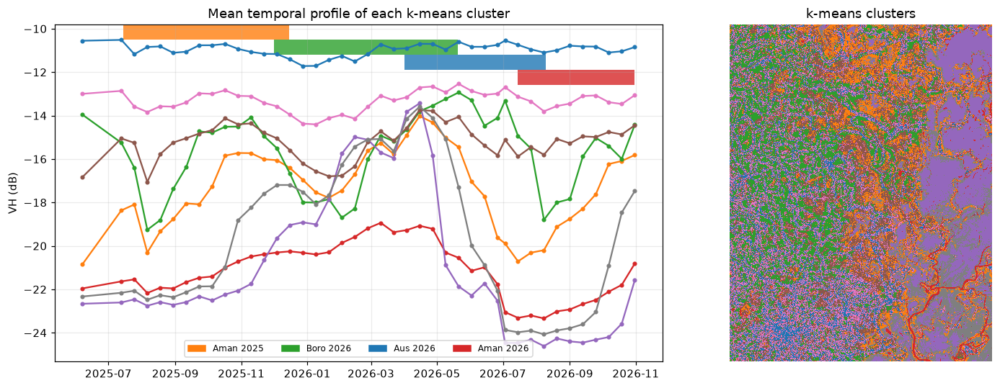

rule class,Aman 2025 → Boro 2026,Aman only (2025 and/or 2026),Aus 2026,Boro 2026 only,Boro 2026 → Aman 2026,Other land,Permanent water,Trees and settlements
cluster,,,,,,,,
0,0.0,0.0,0.0,0.0,0.0,9.0,0.0,91.0
1,4.0,61.0,0.0,6.0,17.0,10.0,0.0,2.0
2,0.0,94.0,0.0,0.0,1.0,4.0,0.0,1.0
3,0.0,3.0,0.0,5.0,0.0,26.0,65.0,2.0
4,0.0,0.0,0.0,81.0,0.0,18.0,0.0,0.0
5,3.0,43.0,3.0,4.0,4.0,36.0,0.0,8.0
6,0.0,5.0,1.0,0.0,0.0,44.0,0.0,51.0
7,2.0,25.0,0.0,32.0,5.0,36.0,0.0,0.0


In [23]:
vh_cube = vh_db.to_dataset(name="vh").to_array("band")      # (band, time, y, x)
kfeat = xr.Dataset({f"vh_{i:02d}": vh_db.isel(time=i, drop=True) for i in range(T)})  # one band per VH date
K = 8  # number of clusters
t0 = time.time()  # start the timer
# mini-batch k-means on 200,000 sampled pixels
km_map, km = ic.unsupervised_classify(kfeat, n_classes=K, method="minibatch_kmeans", sample=200_000, seed=SEED)
print(f"k-means done in {time.time() - t0:.0f} s")  # time taken
cm_means = km.cluster_means_.to_numpy()  # mean profile of each cluster
order = np.argsort(cm_means[:, :].mean(1))  # clusters by mean backscatter
sizes = [(km_map.values == k).mean() * 100 for k in range(K)]  # share of each cluster

fig, ax = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.3, 1]})  # two panels
cmap_k = plt.get_cmap("tab10")  # cluster colours
for k in range(K):  # each cluster
    # its mean profile
    ax[0].plot(vh_db.time, cm_means[k], "-o", ms=3, color=cmap_k(k), label=f"cluster {k} ({sizes[k]:.1f} %)")
# labels, title and legend
ax[0].set_ylabel("VH (dB)"); ax[0].set_title("Mean temporal profile of each k-means cluster"); ax[0].legend(fontsize=7, ncol=2)
seasons_bar(ax[0])  # season bands
# the cluster map
ax[1].imshow(km_map.values, cmap=ListedColormap([cmap_k(k) for k in range(K)]), interpolation="nearest")
ax[1].set_title("k-means clusters"); ax[1].axis("off")  # title, no axes
plt.tight_layout(); plt.show()  # arrange and draw

# which rule class dominates each cluster
ct = pd.crosstab(pd.Series(km_map.values.ravel(), name="cluster"),
                 pd.Series([CLASSES[c] for c in cls_rule.ravel()], name="rule class"), normalize="index").mul(100).round(0)
ct  # share of each rule class per cluster

**Reading the clusters.** The table gives, for each cluster, the share of its pixels that fall in each rule class. Clusters whose rows are dominated by one rule class show that the unsupervised structure and the calendar rules agree; clusters split across several rule classes show where they disagree. k-means knows nothing about the calendar, so its clusters are not named crops and their boundaries do not follow the season definitions. We use it only as an independent, label-free check of the rule map.


## Supervised classification with Random Forest


**Training labels.** Paddy classes come from the *strict* rules, trees and built-up (one class, because VH cannot separate them) from WorldCover, permanent water from the SAR frequency layer, and **other land** from pixels that fail even the loose rules. Pixels that pass the loose rules but not the strict ones are *ambiguous* and are excluded.

**Features.** The 42 VH and 42 VV dB values plus ten temporal statistics, about 94 features per pixel.

**Split.** Pixels are sampled per class (at most 6 000 each) and assigned to train or test by **2 km spatial blocks** (`ic.spatial_block_split`), with `ic.check_split_isolation` confirming no block is shared.


In [24]:
amb = np.zeros(cls_rule.shape, bool)  # ambiguous pixels
paddy_rule = np.isin(cls_rule, [2, 3, 4, 5, 6])  # paddy in the loose map
amb = paddy_rule & ~np.isin(cls_strict, [2, 3, 4, 5, 6])  # paddy in the loose map but not in the strict map
# training labels: strict paddy, other rule classes, ambiguous as -1
labels_map = np.where(amb, -1, np.where(np.isin(cls_strict, [2, 3, 4, 5, 6]), cls_strict, cls_rule)).astype("int16")
# pixels per training class
print("training pool (pixels):", pd.Series(labels_map[labels_map > 0]).map(CLASSES).value_counts().to_dict())

# feature cube as a Dataset of 2-D bands (the format predict_map expects)
feat = xr.Dataset({f"vh_{i:02d}": vh_db.isel(time=i, drop=True) for i in range(T)})
feat.update({f"vv_{i:02d}": vv_db.isel(time=i, drop=True) for i in range(T)})  # add the VV dates
for k, v in feat_stats.data_vars.items():  # add the ten temporal statistics
    feat[k] = v  # ...
feat_names = list(feat.data_vars)  # feature names
print(len(feat_names), "features")  # how many

MAX_PER_CLASS = 6000  # at most 6000 pixels per class
idx = []  # sampled indices
for c in CLASSES:  # each class
    ii = np.flatnonzero(labels_map.ravel() == c)  # its pixels
    if ii.size:  # present
        idx.append(rng.choice(ii, min(MAX_PER_CLASS, ii.size), replace=False))  # a random subset
idx = np.concatenate(idx)  # all sampled indices
rr, cc = np.unravel_index(idx, labels_map.shape)  # their rows and columns
y_all = labels_map[rr, cc]  # their labels
xs, ys = feat.x.values[cc], feat.y.values[rr]  # map coordinates
coords = np.column_stack([xs, ys])  # as (x, y) pairs
F = np.stack([feat[n].values[rr, cc] for n in feat_names], 1)  # feature values
X_all = pd.DataFrame(F, columns=feat_names)  # as a table

# 70 / 30 split by 2 km blocks
split = ic.spatial_block_split(coords, block_size=2000, test_size=0.3, seed=SEED, stratify=y_all)
blocks = ic.spatial_blocks(coords, 2000)  # block id of every sample
ic.check_split_isolation(train=blocks[split.train], test=blocks[split.test])  # no block in both sets
print(f"train {len(split.train):,} px / test {len(split.test):,} px; blocks shared: 0")  # split sizes
# samples per class and split
print(pd.DataFrame({"train": pd.Series(y_all[split.train]).map(CLASSES).value_counts(),
                    "test": pd.Series(y_all[split.test]).map(CLASSES).value_counts()}).fillna(0).astype(int))

training pool (pixels): {'Other land': 1183290, 'Aman only (2025 and/or 2026)': 1181236, 'Trees and settlements': 989255, 'Boro 2026 only': 470931, 'Permanent water': 76658, 'Aus 2026': 30316, 'Boro 2026 → Aman 2026': 22894, 'Aman 2025 → Boro 2026': 16824}
94 features


train 33,531 px / test 14,469 px; blocks shared: 0
                              train  test
Aman 2025 → Boro 2026          4159  1841
Aman only (2025 and/or 2026)   4128  1872
Aus 2026                       4006  1994
Boro 2026 only                 4031  1969
Boro 2026 → Aman 2026          4399  1601
Other land                     4213  1787
Permanent water                4402  1598
Trees and settlements          4193  1807


In [25]:
t0 = time.time()  # start the timer
# random forest with 4-fold spatial CV on the training blocks
rf, cv = ic.train_pixel_classifier(X_all.iloc[split.train], y_all[split.train], model="rf",
                                   coords=coords[split.train], block_size=2000, n_splits=4,
                                   n_estimators=200, n_jobs=-1, seed=SEED)
print(f"trained in {time.time() - t0:.0f} s; spatial 4-fold CV on the training blocks:")  # time taken
print(cv[["accuracy", "macro_f1", "kappa"]].agg(["mean", "std"]).round(3))  # mean and spread of the CV scores
pred_te = rf.predict(X_all.iloc[split.test])  # predict the held-out blocks
# report with 200 bootstrap repeats
rep_rf = ic.classification_report(y_all[split.test], pred_te, labels=list(CLASSES), class_names=CLASSES, n_boot=200)
# headline scores
print(f"\nheld-out blocks: OA {rep_rf['overall_accuracy']:.3f}, kappa {rep_rf['kappa']:.3f}, macro-F1 {rep_rf['macro_f1']:.3f}")
rep_rf["per_class"].round(3)  # per-class scores

trained in 15 s; spatial 4-fold CV on the training blocks:
      accuracy  macro_f1  kappa
mean     0.871     0.869  0.852
std      0.009     0.008  0.011



held-out blocks: OA 0.876, kappa 0.858, macro-F1 0.876


,precision,recall,f1,support,f1_ci_low,f1_ci_high
Permanent water,0.965,0.999,0.982,1598,0.978,0.987
Boro 2026 only,0.944,0.884,0.913,1969,0.905,0.922
Aman 2025 → Boro 2026,0.833,0.815,0.824,1841,0.810,0.836
Boro 2026 → Aman 2026,0.779,0.874,0.824,1601,0.810,0.838
Aman only (2025 and/or 2026),0.924,0.880,0.902,1872,0.891,0.910
Aus 2026,0.869,0.933,0.900,1994,0.891,0.909
Trees and settlements,0.857,0.859,0.858,1807,0.846,0.870
Other land,0.839,0.768,0.802,1787,0.788,0.816


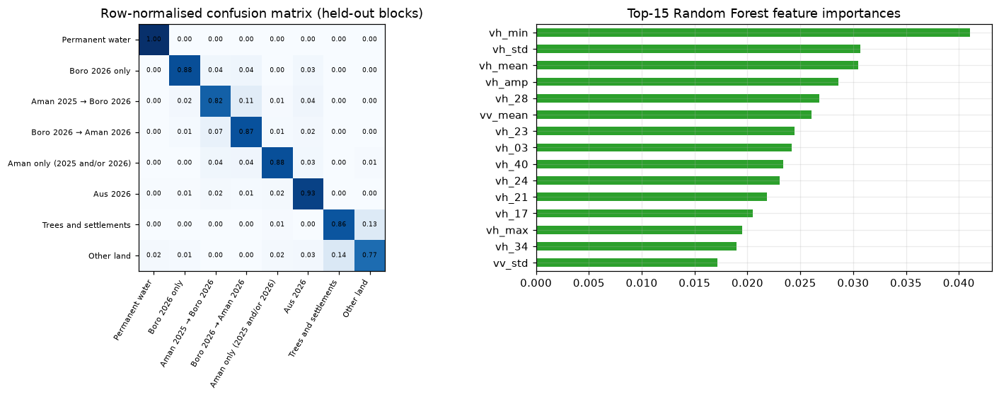

In [26]:
cmx = rep_rf["confusion_matrix"]  # confusion matrix
fig, ax = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.1, 1]})  # two panels
cmn = cmx.div(cmx.sum(1).replace(0, np.nan), axis=0)  # row shares
im = ax[0].imshow(cmn.values, cmap="Blues", vmin=0, vmax=1)  # as colours
# predicted classes
ax[0].set_xticks(range(len(cmx))); ax[0].set_xticklabels(cmx.columns, rotation=60, ha="right", fontsize=7)
ax[0].set_yticks(range(len(cmx))); ax[0].set_yticklabels(cmx.index, fontsize=7)  # reference classes
for i in range(len(cmx)):  # every cell ...
    for j in range(len(cmx)):  # ...
        # its share
        ax[0].text(j, i, f"{cmn.values[i, j]:.2f}" if np.isfinite(cmn.values[i, j]) else "", ha="center", va="center", fontsize=6)
ax[0].set_title("Row-normalised confusion matrix (held-out blocks)"); ax[0].grid(False)  # title, no grid
# 15 most important features
imp = pd.Series(rf.model.feature_importances_, index=feat_names).sort_values(ascending=False).head(15)
# bar chart and title
imp.iloc[::-1].plot.barh(ax=ax[1], color="tab:green"); ax[1].set_title("Top-15 Random Forest feature importances")
plt.tight_layout(); plt.show()  # arrange and draw

RF map of 5.0 M pixels in 22 s


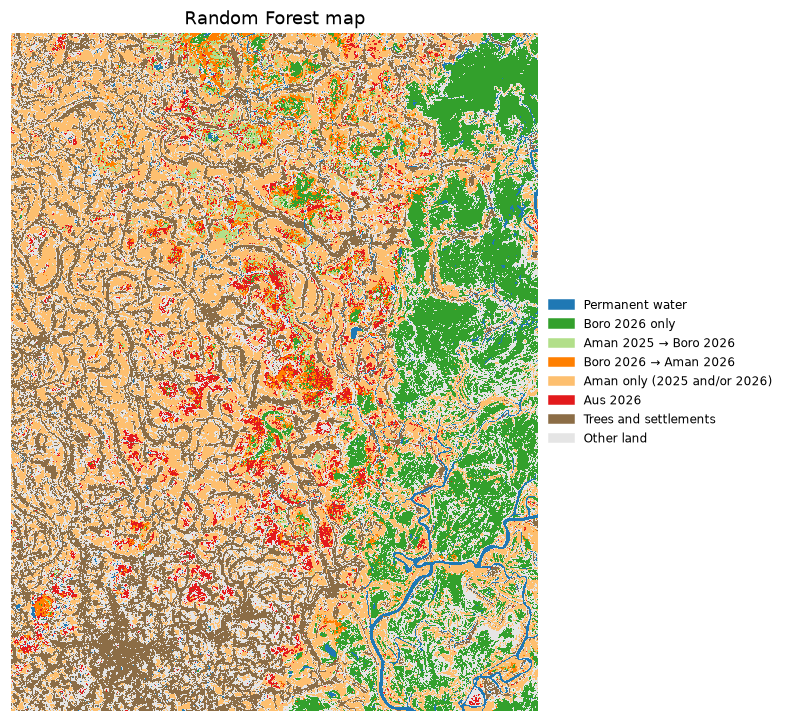

In [27]:
t0 = time.time()  # start the timer
rf_map = ic.predict_map(rf, feat[feat_names], chunk_rows=256)  # classify every pixel in chunks
cls_rf = rf_map.values.astype("int16")  # as integers
print(f"RF map of {cls_rf.size / 1e6:.1f} M pixels in {time.time() - t0:.0f} s")  # size and time
fig, ax = plt.subplots(figsize=(9, 8))  # one panel
show_classes(ax, cls_rf, "Random Forest map"); class_legend(ax); plt.show()  # the RF map and its legend

## Temporal deep learning with a TempCNN


`ic.build_temporal_model("tempcnn")` builds a 1-D CNN over the 42-date sequence of VH and VV (2 channels, in dB). We train it on the **same pixels and the same spatial split** as the Random Forest, so the two held-out scores are comparable. Inputs are standardised with training-set statistics and the loss is class-weighted cross-entropy. A GPU is used when available.


device: cuda


trained 25 epochs in 6 s


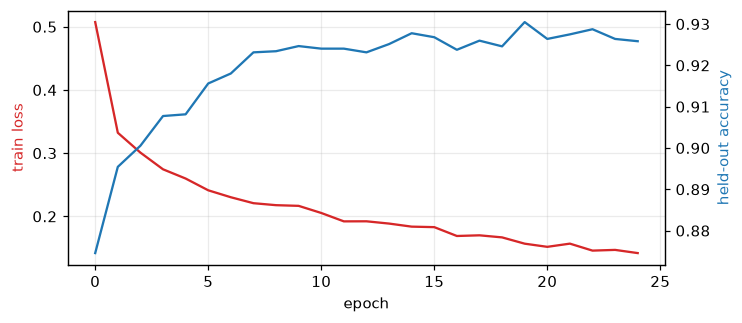

In [28]:
import torch  # PyTorch
dev = "cuda" if torch.cuda.is_available() else "cpu"  # GPU when available
print("device:", dev)  # device

def seq_array(rows, cols):  # (N, T, 2) VH/VV series of the given pixels
    return np.stack([vh_db.values[:, rows, cols].T, vv_db.values[:, rows, cols].T], -1).astype("float32")  # (N, T, 2)

Xs = seq_array(rr, cc)  # series of the sampled pixels
mu, sd = Xs[split.train].mean((0, 1)), Xs[split.train].std((0, 1))  # mean and spread from the training pixels
code_to_idx = {c: i for i, c in enumerate(CLASSES)}  # class code -> index 0-7
yi = np.array([code_to_idx[v] for v in y_all])  # indices of every sample
torch.manual_seed(SEED)  # reproducible initial weights
# TempCNN for 2 channels and 8 classes
net = ic.build_temporal_model("tempcnn", in_channels=2, num_classes=len(CLASSES), n_timesteps=T).to(dev)
# inverse class frequencies ...
w = torch.tensor(1.0 / np.bincount(yi[split.train], minlength=len(CLASSES)).clip(1), dtype=torch.float32)
w = (w / w.sum() * len(CLASSES)).to(dev)  # ... normalised to sum to 8
opt = torch.optim.AdamW(net.parameters(), lr=2e-3, weight_decay=1e-4)  # optimiser
lossf = torch.nn.CrossEntropyLoss(weight=w)  # weighted cross-entropy
Xtr = torch.tensor((Xs[split.train] - mu) / sd); ytr = torch.tensor(yi[split.train])  # scaled training data
Xte = torch.tensor((Xs[split.test] - mu) / sd); yte = yi[split.test]  # scaled test data

EPOCHS, BS = 25, 512  # epochs and batch size
hist = []  # loss and accuracy per epoch
t0 = time.time()  # start the timer
for ep in range(EPOCHS):  # each epoch
    net.train(); perm = torch.randperm(len(Xtr)); tot = 0  # training mode; shuffled order
    for i in range(0, len(perm), BS):  # each batch
        b = perm[i:i + BS]  # its indices
        # one optimisation step
        opt.zero_grad(); loss = lossf(net(Xtr[b].to(dev)), ytr[b].to(dev)); loss.backward(); opt.step(); tot += loss.item() * len(b)
    net.eval()  # evaluation mode
    with torch.no_grad():  # no gradients needed
        # test predictions in chunks
        pt = torch.cat([net(Xte[i:i + 4096].to(dev)).argmax(1).cpu() for i in range(0, len(Xte), 4096)]).numpy()
    hist.append((tot / len(Xtr), (pt == yte).mean()))  # record loss and accuracy
print(f"trained {EPOCHS} epochs in {time.time() - t0:.0f} s")  # time taken
h = pd.DataFrame(hist, columns=["train_loss", "test_acc"])  # as a table
# loss on the left axis
fig, ax = plt.subplots(figsize=(7, 3)); h.train_loss.plot(ax=ax, color="tab:red"); ax.set_ylabel("train loss", color="tab:red")
# accuracy on the right axis
ax2 = ax.twinx(); h.test_acc.plot(ax=ax2, color="tab:blue"); ax2.set_ylabel("held-out accuracy", color="tab:blue"); ax2.grid(False)
ax.set_xlabel("epoch"); plt.show()  # label and draw

TempCNN held-out blocks: OA 0.926, kappa 0.915, macro-F1 0.925

Per-class F1 on the same held-out blocks:
                              RF F1  TempCNN F1
Permanent water               0.982       0.987
Boro 2026 only                0.913       0.965
Aman 2025 → Boro 2026         0.824       0.919
Boro 2026 → Aman 2026         0.824       0.911
Aman only (2025 and/or 2026)  0.902       0.949
Aus 2026                      0.900       0.975
Trees and settlements         0.858       0.866
Other land                    0.802       0.825


TempCNN map in 8 s


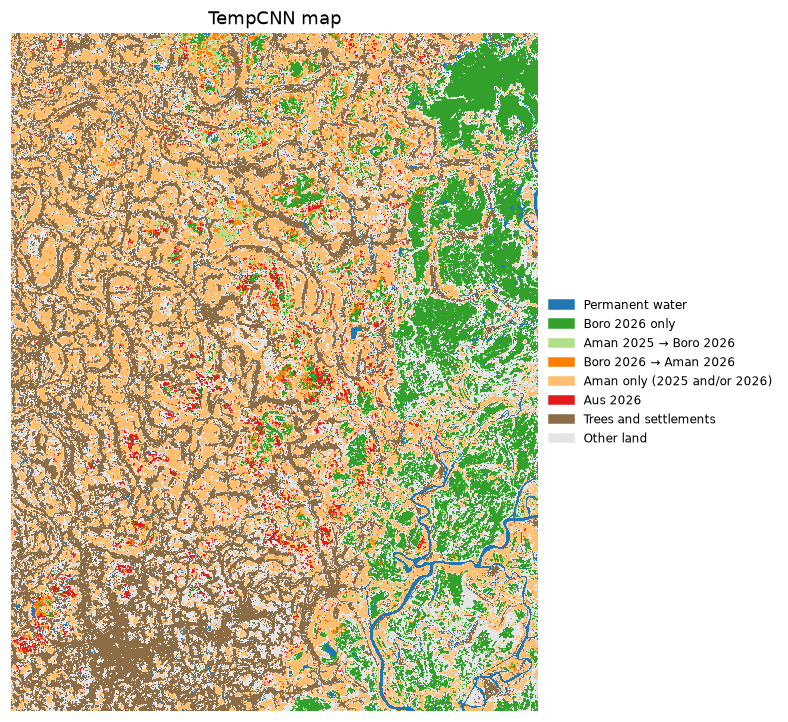

In [29]:
idx_to_code = {i: c for c, i in code_to_idx.items()}  # index -> class code
pred_cnn = np.array([idx_to_code[i] for i in pt])  # predicted codes
# report with 200 bootstrap repeats
rep_cnn = ic.classification_report(y_all[split.test], pred_cnn, labels=list(CLASSES), class_names=CLASSES, n_boot=200)
# headline scores
print(f"TempCNN held-out blocks: OA {rep_cnn['overall_accuracy']:.3f}, kappa {rep_cnn['kappa']:.3f}, macro-F1 {rep_cnn['macro_f1']:.3f}")
# per-class F1 of both models
cmp_ = pd.DataFrame({"RF F1": rep_rf["per_class"]["f1"], "TempCNN F1": rep_cnn["per_class"]["f1"]})
print("\nPer-class F1 on the same held-out blocks:"); print(cmp_.round(3))  # header and table

# predict the whole window in batches
t0 = time.time()
H, W_ = wc_arr.shape  # grid size
pred_full = np.empty(H * W_, "int16")  # output array
vh_flat = vh_db.values.reshape(T, -1); vv_flat = vv_db.values.reshape(T, -1)  # VH and VV as (T, pixels)
net.eval()  # evaluation mode
with torch.no_grad():  # no gradients needed
    for i in range(0, H * W_, 200_000):  # batches of 200,000 pixels
        xb = np.stack([vh_flat[:, i:i + 200_000].T, vv_flat[:, i:i + 200_000].T], -1)  # their series
        xb = torch.tensor((xb - mu) / sd, dtype=torch.float32).to(dev)  # scaled, on the device
        pred_full[i:i + 200_000] = [idx_to_code[j] for j in net(xb).argmax(1).cpu().numpy()]  # predicted codes
cls_cnn = pred_full.reshape(H, W_)  # as a map
print(f"TempCNN map in {time.time() - t0:.0f} s")  # time taken
# the map and its legend
fig, ax = plt.subplots(figsize=(9, 8)); show_classes(ax, cls_cnn, "TempCNN map"); class_legend(ax); plt.show()

## Comparing the maps and cleaning the result


Area per class (km²)
                              Rules  Random Forest  TempCNN
Permanent water                  31             41       37
Boro 2026 only                  310            281      268
Aman 2025 → Boro 2026            25             41       19
Boro 2026 → Aman 2026            60             53       22
Aman only (2025 and/or 2026)    670            544      544
Aus 2026                         15             83       45
Trees and settlements           396            400      489
Other land                      473            538      555

Pixel agreement between maps (%)
               Rules  Random Forest  TempCNN
Rules          100.0           80.2     79.1
Random Forest   80.2          100.0     84.0
TempCNN         79.1           84.0    100.0


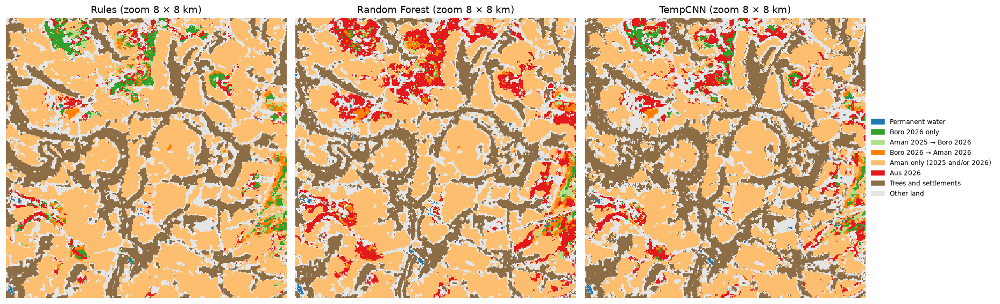

In [30]:
maps = {"Rules": cls_rule, "Random Forest": cls_rf, "TempCNN": cls_cnn}  # the three maps
rows = {}  # area per class
for name, m in maps.items():  # each map
    cnt = pd.Series(m.ravel()).value_counts()  # pixels per class
    rows[name] = {CLASSES[k]: cnt.get(k, 0) * 4e-4 for k in CLASSES}  # in km2
area_cmp = pd.DataFrame(rows).round(0).astype(int)  # as a table
print("Area per class (km²)"); print(area_cmp)  # header and table
# pixel agreement between every pair
agree = pd.DataFrame({a: {b: (maps[a] == maps[b]).mean() * 100 for b in maps} for a in maps}).round(1)
print("\nPixel agreement between maps (%)"); print(agree)  # header and table

fig, ax = plt.subplots(1, 3, figsize=(17, 6))  # three panels
rect = (slice(1300, 1700), slice(500, 900))  # an 8 x 8 km zoom
for a, (name, m) in zip(ax, maps.items()):  # each map
    show_classes(a, m[rect], f"{name} (zoom 8 × 8 km)")  # its zoom
class_legend(ax[2]); plt.tight_layout(); plt.show()  # legend, arrange and draw

### Cleaning and vectorising

Isolated pixels are salt-and-pepper noise left by residual speckle. We take the **Random Forest** map, remove paddy objects smaller than 25 pixels (1 ha, a small field) and fill holes of the same size with `ic.clean_mask`, then label the connected patches of each paddy class and convert them to polygons with `ic.polygonize` (patches of 1 ha or more). A polygon is a **patch of connected paddy pixels of one class**, not a surveyed field boundary: neighbouring fields of the same class merge.


In [31]:
PADDY = [2, 3, 4, 5, 6]  # the paddy classes
tmpl = vh_db.isel(time=0, drop=True)  # a 2-D template
clean = cls_rf.copy()  # a copy of the RF map
for c in PADDY:  # each paddy class
    m = clean == c  # its pixels
    # drop patches and holes smaller than 25 pixels
    keep = ic.clean_mask(m, min_size=25, hole_size=25, opening=0).astype(bool)
    clean[m & ~keep] = 8  # removed pixels become "Other land"
clean_da = tmpl.copy(data=clean.astype("int32")).rename("class")  # as a DataArray
removed = (cls_rf != clean).sum()  # pixels changed
print(f"pixels relabelled by clean-up: {removed:,} ({removed / clean.size * 100:.2f} %)")  # report

t0 = time.time()  # start the timer
from scipy import ndimage as ndi  # connected-component labelling
inst = np.zeros(clean.shape, "int32")             # one id per connected patch of one paddy class
n_inst = 0  # instance ids so far
for c in PADDY:  # each paddy class
    lab, n = ndi.label(clean == c)  # its connected patches
    inst[lab > 0] = lab[lab > 0] + n_inst  # unique ids
    n_inst += n  # next free id
inst_da = tmpl.copy(data=inst).rename("instance")  # as a DataArray
# polygons of at least 1 ha, simplified by 10 m
polys = ic.polygonize(inst_da, class_map=clean_da, class_names=CLASSES, min_area=10_000, simplify=10)
# numbers and time
print(f"{n_inst:,} connected patches, {len(polys):,} polygons of at least 1 ha in {time.time() - t0:.0f} s")
# count, median size and area per class
polys.groupby("class_name").agg(n=("id", "size"), median_ha=("area", lambda a: np.median(a) / 1e4), total_km2=("area", lambda a: a.sum() / 1e6)).round(2)

pixels relabelled by clean-up: 206,748 (4.18 %)


6,900 connected patches, 6,846 polygons of at least 1 ha in 13 s


,n,median_ha,total_km2
class_name,,,
Aman 2025 → Boro 2026,663,2.00,28.24
Aman only (2025 and/or 2026),3336,3.68,515.43
Aus 2026,1130,2.24,65.03
Boro 2026 only,896,2.84,270.30
Boro 2026 → Aman 2026,821,2.12,39.55


## Area and timing statistics by district


Areas are counted from the cleaned Random Forest map (each pixel is 20 × 20 m = 0.04 ha). **They are map areas, not area estimates**: without a probability sample of reference points, we cannot apply the Olofsson et al. (2014) estimator (`classify.olofsson`) to correct them for classification error, and we do not report confidence intervals. The districts are rasterised onto the window grid; pixels outside the three districts are ignored.


In [32]:
x0, y0 = float(win.x[0]), float(win.y[0])  # centre of the first pixel
transform = Affine(WIN_RES, 0, x0 - WIN_RES / 2, 0, -WIN_RES, y0 + WIN_RES / 2)  # the window's geotransform
dist_ids = {n: i + 1 for i, n in enumerate(dist_win["shapeName"])}  # district name -> id
# district raster on the window grid
dist_raster = rfeat.rasterize([(g, dist_ids[n]) for g, n in zip(dist_win.geometry, dist_win["shapeName"])],
                              out_shape=clean.shape, transform=transform, fill=0, dtype="int16")
rows = []  # one row per district
for n, i in dist_ids.items():  # each district
    m = dist_raster == i  # its pixels
    r = {"district": n, "window km²": m.sum() * 4e-4}  # its area in the window
    for c in PADDY:  # each paddy class
        r[CLASSES[c]] = ((clean == c) & m).sum() * 4e-4  # its area in the district
    r["Paddy total km²"] = sum(r[CLASSES[c]] for c in PADDY)  # total paddy
    r["paddy % of district part"] = r["Paddy total km²"] / r["window km²"] * 100  # paddy share
    rows.append(r)  # keep the row
stats = pd.DataFrame(rows).set_index("district").round(1)  # as a table
stats  # show it

,window km²,Boro 2026 only,Aman 2025 → Boro 2026,Boro 2026 → Aman 2026,Aman only (2025 and/or 2026),Aus 2026,Paddy total km²,paddy % of district part
district,,,,,,,,
Kishoreganj,768.7,114.7,2.9,8.4,167.7,24.6,318.3,41.4
Mymensingh,179.5,0.0,0.2,0.4,56.9,3.3,60.9,33.9
Netrakona,1032.1,155.6,25.2,30.7,290.8,37.0,539.4,52.3


In [33]:
rows = []  # one row per district
for n, i in dist_ids.items():  # each district
    m = (dist_raster == i) & ~np.isnat(loose["boro_harvest_date"])  # Boro pixels with a harvest date
    hd = pd.Series(pd.to_datetime(loose["boro_harvest_date"][m]))  # their harvest dates
    td = pd.Series(pd.to_datetime(loose["boro_date"][m]))  # their transplanting dates
    # medians and the share harvested by 27 April
    rows.append({"district": n, "Boro px": int(m.sum()), "median flood-minimum": td.median().date(),
                 "median harvest": hd.median().date(),
                 "harvest ≤ 27 Apr (%)": float((hd <= pd.Timestamp("2026-04-27")).mean() * 100)})
pd.DataFrame(rows).set_index("district").round(1)  # as a table

,Boro px,median flood-minimum,median harvest,harvest ≤ 27 Apr (%)
district,,,,
Kishoreganj,377598,2026-01-09,2026-05-09,7.3
Mymensingh,7219,2026-01-21,2026-05-09,4.7
Netrakona,607959,2025-12-28,2026-05-09,26.8


## Writing the outputs


In [34]:
colormap = {k: tuple(int(PALETTE[k][i:i + 2], 16) for i in (1, 3, 5)) for k in CLASSES}  # class -> RGB colour
# provenance written into the files
meta = {"source": "Sentinel-1 RTC (Planetary Computer), relative orbit 150", "period": "2025-06-07 to 2026-10-31",
        "dates": str(T), "note": "no field reference data; paddy classes are rule-derived"}
rt = vh_db.rio.write_crs(CRS)  # VH with its CRS
written = []  # files written
# the three maps
for name, arr in [("paddy_rules", cls_rule), ("paddy_random_forest", clean), ("paddy_tempcnn", cls_cnn)]:
    da = tmpl.copy(data=arr.astype("int32")).rio.write_crs(CRS)  # as a georeferenced raster
    # write as a GeoTIFF with classes and colours
    written.append(ic.write_class_map(da, OUT / f"{name}_haor_20m.tif", class_names=CLASSES, colormap=colormap, metadata=meta))

def date_tif(path, dates, ref):  # write a date map as days since a reference date
    # days since ref, NaN where no date
    a = np.where(np.isnat(dates), np.nan, (dates - np.datetime64(ref)).astype(float)).astype("float32")
    # georeference and describe it
    da = tmpl.copy(data=a).rio.write_crs(CRS); da.attrs = {"description": f"days since {ref}"}
    da.rio.to_raster(path, compress="deflate"); written.append(Path(path))  # write it
# Boro transplanting dates
date_tif(OUT / "boro_flood_minimum_date_days_since_2025-12-01.tif", loose["boro_date"], "2025-12-01")
# Boro harvest dates
date_tif(OUT / "boro_harvest_date_days_since_2026-04-15.tif", loose["boro_harvest_date"], "2026-04-15")

# the paddy polygons
polys.to_file(OUT / "paddy_fields_haor.gpkg", layer="paddy", driver="GPKG"); written.append(OUT / "paddy_fields_haor.gpkg")
# district statistics
stats.to_csv(OUT / "paddy_area_by_district.csv"); written.append(OUT / "paddy_area_by_district.csv")
# the Sentinel-1 inventory
inv.to_csv(OUT / "sentinel1_inventory.csv"); written.append(OUT / "sentinel1_inventory.csv")
# held-out F1 of both models
pd.DataFrame({"RF": rep_rf["per_class"]["f1"], "TempCNN": rep_cnn["per_class"]["f1"]}).to_csv(OUT / "heldout_f1.csv")
for p in written:  # every file ...
    print(f"{p.name:62s} {p.stat().st_size / 1e6:8.2f} MB")  # ... with its size

paddy_rules_haor_20m.tif                                           0.81 MB
paddy_random_forest_haor_20m.tif                                   0.75 MB
paddy_tempcnn_haor_20m.tif                                         0.82 MB
boro_flood_minimum_date_days_since_2025-12-01.tif                  0.82 MB
boro_harvest_date_days_since_2026-04-15.tif                        0.58 MB
paddy_fields_haor.gpkg                                            11.53 MB
paddy_area_by_district.csv                                         0.00 MB
sentinel1_inventory.csv                                            0.00 MB


## Interpretation, caveats and recommended recipe


**What the measured numbers say** (haor window, 1,980 km², 20 m, 42 dates, VH/VV after multi-temporal Lee filtering):

* **The Boro signature in the haors is the whole annual cycle.** Wetland pixels (WorldCover 90) sit near −22 dB VH from June to December (monsoon flood), rise from January to a peak near −13 dB in April, and drop sharply at harvest in May. The loose Boro rule flags 86 % of wetland pixels, 22 % of cropland and almost no trees or built-up; Boro-only covers about 310 km² (rule map), with Netrokona (≈156 km²) and Kishoreganj (≈115 km²) holding nearly all of it and Mymensingh essentially none in the window.
* **Aman is the dominant paddy class on the uplands** (≈670 km² in the rule map, ≈545 km² in both supervised maps). Aus is poorly constrained: 15 km² by rules but 44 to 83 km² in the classifiers, so treat Aus areas as unreliable.
* **Supervised scores measure reproduction of rule-derived labels, not accuracy.** On spatially held-out 2 km blocks, the Random Forest reaches OA 0.876 (kappa 0.858, macro-F1 0.876; spatial 4-fold CV 0.871 ± 0.009) and the TempCNN OA 0.926 (kappa 0.915, macro-F1 0.925). The TempCNN's advantage is largest for the transition classes (Aman 2025 → Boro 0.92 vs 0.82). Because the labels come from the same rules, a higher score can mean only that a model copies the rules better. The three maps agree on 79 to 84 % of pixels, which is a consistency measure, not a validation.
* **Smoothing and noise.** ENL over a homogeneous cropland block is 5.9 (raw), 21.1 (single-date Lee) and 14.8 (multi-temporal Lee). The single-date filter reduces noise more but smooths space more; we prefer the multi-temporal filter because it keeps small features and each pixel's own time series. ENL does not measure edge preservation.
* **Water.** The SAR permanent-water layer (1.55 % of the window) recovers most JRC water (recall 0.78) but has low precision (0.37) and an IoU of only 0.33 against JRC ≥ 80 %, and IoU 0.37 against WorldCover water. The sources disagree, and we have no reference to settle which is right.
* **Platform consistency.** Tree-cover VH differs by +0.09 dB between Sentinel-1A and 1D (overall SD 0.30 dB), and no date is flagged by the stable-target check, so the series is treated as one.
* **Polygons are connected patches, not fields.** 6,846 patches of at least 1 ha (median 2 to 4 ha) were produced, but neighbouring fields of the same class merge, so they cannot be used as field boundaries or for field counts.

**Caveats**

* **No field reference data were used.** Every class except water and trees/settlements is defined by thresholds on the SAR time series (the loose and strict rules). There is no accuracy statement and no Olofsson area-and-uncertainty estimate for any map.
* **Weak labels for trees/settlements.** They come from ESA WorldCover 2021 and are merged into one class because VH cannot separate them. They are not time-matched to 2025 to 26.
* **Date count.** The query returned 42 dates on relative orbit 150, not 41. The extra one is 7 June 2025, which is followed by a 36-day gap to 13 July 2025; the first Aman 2025 stage is therefore sampled sparsely.
* **Aman 2026 is early-season only.** The series ends on 31 October 2026, so Aman 2026 cannot be seen through to harvest.
* **Single track, single orbit direction** (descending, 150): dew, wind and soil moisture at the fixed acquisition time affect the series, and the 20 m pixels are coarse for fields of 0.1 to 0.5 ha, so mixed pixels are expected, especially at field edges.
* **Flood confusion.** In deep-flooded haors, open-water backscatter and flooded rice can be similar for months. Boro is identified from the later cycle and harvest drop, not from the flood stage itself.
* **The harvest-drop rule is ours** (4 dB loose, 5 dB strict) and is not part of GeoLattice; the thresholds were chosen by inspecting signatures, not calibrated.
* **Region.** Only the haor window was mapped at 20 m. The 200 m regional view is for context and was not classified.

**Recommended recipe and next steps**

1. Filter with `s1.multitemporal_speckle_filter` and convert to dB; use VH as the main channel and VV for flooded-vegetation checks.
2. Build the temporal features, derive the strict rule labels, and train a pixel classifier (Random Forest as the baseline; TempCNN if a GPU is available), always with a **spatial block split** and `ic.check_split_isolation`.
3. Clean the map (`ic.clean_mask`) and vectorise connected patches.
4. **Collect field reference data** (a probability sample of points or fields, with crop and sowing/harvest dates for 2025 to 26), then replace the rule-derived labels, report a confusion matrix and area estimates with confidence intervals (Olofsson et al., 2014).
5. Add a Sentinel-2 optical time series (NDVI/LSWI) or ascending-orbit Sentinel-1 data to reduce flood and mixed-pixel confusion, and recalibrate the harvest-drop thresholds against the reference data.
